# **Goal for Round 2: ** 

This notebook tries to discover better & meaningful answers and visualizations around the following questions:

**What do we know about vaccines and therapeutics? What has been published concerning research and development and evaluation efforts of vaccines and therapeutics?**

**Effectiveness of drugs being developed and tried to treat COVID-19 patients.**

**Clinical and bench trials to investigate less common viral inhibitors against COVID-19 such as naproxen, clarithromycin, and minocyclinethat that may exert effects on viral replication.**

**Methods evaluating potential complication of Antibody-Dependent Enhancement (ADE) in vaccine recipients.**

**Exploration of use of best animal models and their predictive value for a human vaccine.**

**Capabilities to discover a therapeutic (not vaccine) for the disease, and clinical effectiveness studies to discover therapeutics, to include antiviral agents.**

**Alternative models to aid decision makers in determining how to prioritize and distribute scarce, newly proven therapeutics as production ramps up. This could include identifying approaches for expanding production capacity to ensure equitable and timely distribution to populations in need.**

**Efforts targeted at a universal coronavirus vaccine.**

**Efforts to develop animal models and standardize challenge studies**

**Efforts to develop prophylaxis clinical studies and prioritize in healthcare workers**

**Approaches to evaluate risk for enhanced disease after vaccination**

**Assays to evaluate vaccine immune response and process development for vaccines, alongside suitable animal models in conjunction with therapeutics**

# **About Us:**
We are a group of AI and NLP scientists with experience across NLP, image processing and computer vision. Covid-19 Kaggle challenge has provided us with a unique opportunity to help humanity fight the corona virus pandemic collectively by utilizing benefits of AI and NLP. We have focused on creating NLP solution to enable users to ask questions and get the most accurate results from the vast corpus of medical journals.


# **Approach:**

We have trained the sent2vec model on the most recent dump of CORD-19 corpus to generate sentence embeddings. This model is trained on 14658255 sentences and 864320 words. **Fasttext embeddings are huge in size so we could not generate this in the working directory of the kernel.** We trained our model on AWS and uploaded the same as additional dataset.

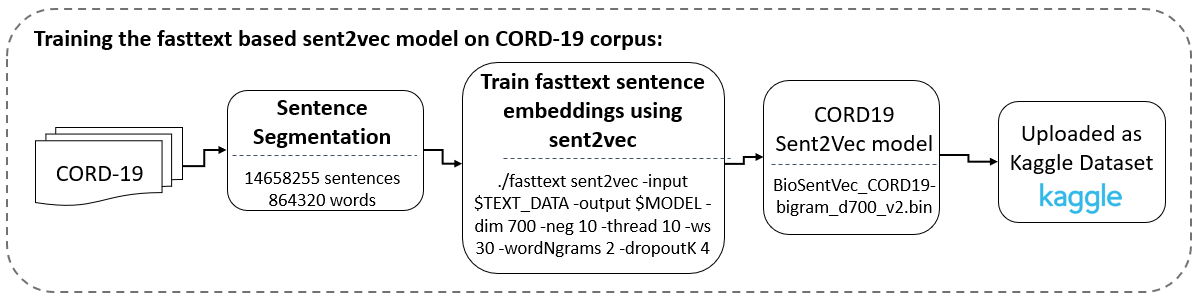

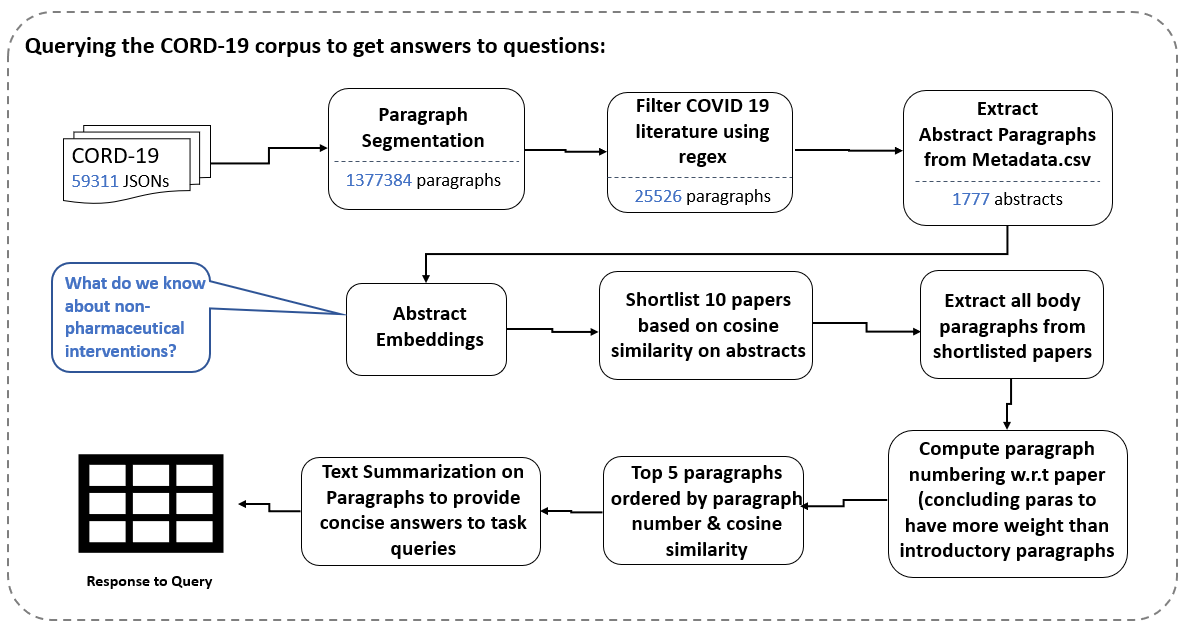

# Benefits of this approach:

* Very simple and straightforward approach without complex indexing and other dependencies which need to be set up
* Based on FastText Sent2Vec embeddings trained on CORD-19 corpus - embeddings are contextually relevant to the queries
* Filtering helps remove lots of non-covid content
* Text summarization helps to summarize longer paragraphs

# Further Improvements possible:
* Embeddings are currently computed on entire paragraphs rather than at sentence level. Aggregating sentence level embeddings at paragraph level would be more relevant
* Currently only looks for answers in papers which have abstracts available in the metadata.csv. Approach needs to be further scaled to entire literature
* Disease names can be further extracted using spacy medical NER models that can add further structure to the response

# Install and set-up dependencies

In [1]:
!pip install https://s3-us-west-2.amazonaws.com/ai2-s2-scispacy/releases/v0.2.4/en_core_sci_sm-0.2.4.tar.gz
!pip install scispacy
!git clone https://github.com/epfml/sent2vec.git

     |████████████████████████████████| 17.0 MB 1.1 MB/s 
  Created wheel for en-core-sci-sm: filename=en_core_sci_sm-0.2.4-py3-none-any.whl size=17161107 sha256=83f64ff0b52f5c919433285fd0439281376bf8f7c2caa60698dba93537e95a9e
  Stored in directory: /root/.cache/pip/wheels/00/68/db/3249441fa3dabcffa9dc399dbaa45e6db588bdde073cfd2dd3
Successfully built en-core-sci-sm
     |████████████████████████████████| 3.0 MB 6.4 MB/s 
     |████████████████████████████████| 12.9 MB 21.5 MB/s 
     |████████████████████████████████| 6.2 MB 41.8 MB/s 
     |████████████████████████████████| 46 kB 2.8 MB/s 
  Created wheel for scispacy: filename=scispacy-0.2.4-py3-none-any.whl size=35203 sha256=bb413d3d6efdb871a4b523f63e7245c63a8a96dd9c20966c95a8d4cf3b08b3b0
  Stored in directory: /root/.cache/pip/wheels/80/01/69/37a2ab4f9b61773c187d83257ffb31365a5ad57e7779ae5e92
Successfully built scispacy
ERROR: boto3 1.12.32 has requirement botocore<1.16.0,>=1.15.32, but you'll have botocore 1.16.6 which is incompat

In [2]:
cd sent2vec

/kaggle/working/sent2vec


In [3]:
!pip install .

Processing /kaggle/working/sent2vec
  Created wheel for sent2vec: filename=sent2vec-0.0.0-cp36-cp36m-linux_x86_64.whl size=1135754 sha256=ef33f8c57bdb73343897a4ddbdb23bb9dfa940b7e217d9c23cfc2085d05ad7a9
  Stored in directory: /tmp/pip-ephem-wheel-cache-mmhop85j/wheels/c1/34/ea/5fc9d25ba2a77a4421a32f4ee14dbcc8c90b49e85f7be82982
Successfully built sent2vec


In [4]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load in 

import spacy
import en_core_sci_sm
import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)
import glob
import json
import pandas as pd
from tqdm import tqdm
import re
import spacy
import os
import matplotlib.pyplot as plt
from sklearn.metrics.pairwise import cosine_similarity

pd.options.mode.chained_assignment = None  # default='warn'

# Load the Input JSON files & metadata.csv

In [5]:
# Input data files are available in the "../input/" directory.
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

root_path = '/kaggle/input/CORD-19-research-challenge/'
all_json = glob.glob(f'{root_path}/**/*.json', recursive=True)
print(len(all_json), 'JSON files detected')
metadata_path = f'{root_path}metadata.csv'
meta_df = pd.read_csv(metadata_path, dtype={
    'pubmed_id': str,
    'Microsoft Academic Paper ID': str,
    'doi': str
})
print(len(meta_df), 'files in metadata.csv')
print(meta_df.columns)
meta_df.head(3)

71261 JSON files detected
59887 files in metadata.csv
Index(['cord_uid', 'sha', 'source_x', 'title', 'doi', 'pmcid', 'pubmed_id',
       'license', 'abstract', 'publish_time', 'authors', 'journal',
       'Microsoft Academic Paper ID', 'WHO #Covidence', 'arxiv_id',
       'has_pdf_parse', 'has_pmc_xml_parse', 'full_text_file', 'url'],
      dtype='object')


/opt/conda/lib/python3.6/site-packages/IPython/core/interactiveshell.py:3063: DtypeWarning: Columns (14) have mixed types. Specify dtype option on import or set low_memory=False.
  interactivity=interactivity, compiler=compiler, result=result)


,cord_uid,sha,source_x,title,doi,pmcid,pubmed_id,license,abstract,publish_time,authors,journal,Microsoft Academic Paper ID,WHO #Covidence,arxiv_id,has_pdf_parse,has_pmc_xml_parse,full_text_file,url
0,zjufx4fo,b2897e1277f56641193a6db73825f707eed3e4c9,PMC,Sequence requirements for RNA strand transfer ...,10.1093/emboj/20.24.7220,PMC125340,11742998,unk,Nidovirus subgenomic mRNAs contain a leader se...,2001-12-17,"Pasternak, Alexander O.; van den Born, Erwin; ...",The EMBO Journal,NaN,NaN,NaN,True,True,custom_license,http://europepmc.org/articles/pmc125340?pdf=re...
1,ymceytj3,e3d0d482ebd9a8ba81c254cc433f314142e72174,PMC,"Crystal structure of murine sCEACAM1a[1,4]: a ...",10.1093/emboj/21.9.2076,PMC125375,11980704,unk,CEACAM1 is a member of the carcinoembryonic an...,2002-05-01,"Tan, Kemin; Zelus, Bruce D.; Meijers, Rob; Liu...",The EMBO Journal,NaN,NaN,NaN,True,True,custom_license,http://europepmc.org/articles/pmc125375?pdf=re...
2,wzj2glte,00b1d99e70f779eb4ede50059db469c65e8c1469,PMC,Synthesis of a novel hepatitis C virus protein...,10.1093/emboj/20.14.3840,PMC125543,11447125,no-cc,Hepatitis C virus (HCV) is an important human ...,2001-07-16,"Xu, Zhenming; Choi, Jinah; Yen, T.S.Benedict; ...",EMBO J,NaN,NaN,NaN,True,True,custom_license,https://www.ncbi.nlm.nih.gov/pmc/articles/PMC1...


In [6]:
meta_df['publish_date'] = pd.to_datetime(meta_df['publish_time'], infer_datetime_format=True)
meta_df['publish_date'].head()

0   2001-12-17
1   2002-05-01
2   2001-07-16
3   2002-07-01
4   2002-12-01
Name: publish_date, dtype: datetime64[ns]

In [7]:
# 'source_x', 'license', 'journal', 'has_pdf_parse', 'has_pmc_xml_parse', 'full_text_file'
print("Source:")
print(meta_df['source_x'].value_counts(), '\n')

print("license:")
print(meta_df['license'].value_counts(), '\n')

print("Journal:")
print(meta_df['journal'].value_counts(), '\n')

print("has_pdf_parse:")
print(meta_df['has_pdf_parse'].value_counts(), '\n')

print("has_pmc_xml_parse:")
print(meta_df['has_pmc_xml_parse'].value_counts(), '\n')

print("full_text_file:")
print(meta_df['full_text_file'].value_counts(), '\n')

Source:
PMC         32239
Elsevier    22762
medrxiv      2007
biorxiv      1064
WHO           918
arxiv         797
CZI           100
Name: source_x, dtype: int64 

license:
els-covid      22762
unk            10674
no-cc          10242
cc-by           9534
medrvix         2007
cc-by-nc        1271
biorxiv         1064
arxiv            797
cc-by-nc-nd      772
cc-by-nc-sa      488
cc0              266
cc-by-nd           5
pd                 3
cc-by-sa           2
Name: license, dtype: int64 

Journal:
Journal of Virology                                   1753
PLoS One                                              1576
Virology                                               937
Emerg Infect Dis                                       749
The Lancet                                             688
                                                      ... 
Journal of Financial Markets                             1
Functional Chitosan                                      1
Chikungunya Virus    

# Extract Abstract & Body paragraphs from JSON

In [8]:
##### Keyword patterns to search for
keywords = [r"2019[\-\s]?n[\-\s]?cov", "2019 novel coronavirus", "coronavirus 2019", r"coronavirus disease (?:20)?19",
            r"covid(?:[\-\s]?19)?", r"n\s?cov[\-\s]?2019", r"sars-cov-?2", r"wuhan (?:coronavirus|cov|pneumonia)",
            r"rna (?:coronavirus|cov|pneumonia)", r"mers (?:coronavirus|cov|pneumonia)", r"influenza (?:coronavirus|cov|pneumonia)",
            r"sars (?:coronavirus|cov|pneumonia)", r"sars", r"mers", r"pandemic", r"pandemics"]

covid_keywords = [r"2019[\-\s]?n[\-\s]?cov", "2019 novel coronavirus", "coronavirus 2019", r"coronavirus disease (?:20)?19",
            r"covid(?:[\-\s]?19)?", r"n\s?cov[\-\s]?2019", r"sars-cov-?2", r"wuhan (?:coronavirus|cov|pneumonia)"]

# Build regular expression for each keyword. Wrap term in word boundaries
regex = "|".join(["\\b%s\\b" % keyword.lower() for keyword in keywords])
covid_regex = "|".join(["\\b%s\\b" % keyword.lower() for keyword in covid_keywords])

def tags(text):
    if re.findall(regex, str(text).lower()):
        tags = "COVID-19"
    else:
        tags="NON COVID"
    return tags

def covid_tags(text):
    if re.findall(covid_regex, str(text).lower()):
        tags = "COVID-19"
    else:
        tags="NON COVID"
    return tags


class FileReader:
    def __init__(self, file_path):
        with open(file_path) as file:
            content = json.load(file)
        self.paper_id = content['paper_id']
        self.content = content
        self.abstracts = []
        self.body_texts = []
        self.countries = []
        self.title = ''
        
        if "abstract" in self.content:
            for idx, entry in enumerate(self.content['abstract']):
                if not isinstance(entry['text'], str):
                    continue
                d={}
                d["idx"] = idx
                d["section"] = entry['section']
                d["para"] = entry['text']
                self.abstracts.append(d)
    
        for idx,entry in enumerate(self.content['body_text']):
            if not isinstance(entry['text'], str):
                continue
            d = {}
            d["idx"] = idx
            d["section"] = entry['section']
            d["para"] = entry['text']
            self.body_texts.append(d)
    
        if "metadata" in self.content and "authors" in self.content["metadata"]:
            for idx, author in enumerate(self.content['metadata']['authors']):
                if 'affiliation' in author and 'location' in author['affiliation']:
                    location = author['affiliation']['location']
                    if 'region' in location:
                        self.countries.append(location['region'])
                    elif 'country' in location:
                        self.countries.append(location['country'])
        self.countries = list(set(self.countries))
    
        if "metadata" in self.content and "title" in self.content["metadata"]:
            self.title = self.content["metadata"]["title"]
    
    def __repr__(self):
        return f'{self.paper_id}: {self.abstracts[:2]}... {self.body_texts[:2]}... {self.countries[:]}...'

firstRow = FileReader(all_json[0])
print(firstRow.paper_id)
print(firstRow.title)
print(firstRow.countries)

PMC4492419
Science and technology - human society convergence plan to solve social problems - the new virus explained
[]


Iterate JSON directories to load all the paragraphs from abstracts and body of different papers. Abstracts if available in metadata.csv is also loaded separately.

In [9]:
no_of_files_not_found = 0
dict_ = {
    'cord_uid':[], 'paper_id': [], 'section': [], 'sub_section': [], 'paragraph': [], 'authors': [], 'title': [],
    'journal': [], 'publish_date': [], 'tags':[], 'countries': [], 'source_x': [], 'full_text_file': []
}

for index, meta in tqdm(meta_df.iterrows(), total=meta_df.shape[0]): # 
    has_pdf_parse = meta.has_pdf_parse
    has_pmc_xml_parse = meta.has_pmc_xml_parse
    
    if has_pmc_xml_parse == True:
        full_text_file_path = root_path + meta.full_text_file + '/' + meta.full_text_file + '/pmc_json/' + meta.pmcid + '.xml.json'
    elif has_pdf_parse == True:
        full_text_file_path = root_path + meta.full_text_file + '/' + meta.full_text_file + '/pdf_json/' + meta.sha + '.json'
    
    if os.path.isfile(full_text_file_path) == False:
        no_of_files_not_found += 1
        continue
    
    content = FileReader(full_text_file_path)
    
    cord_uid = meta.cord_uid
    authors = meta.authors
    title = meta.title
    journal = meta.journal
    publish_date = meta.publish_date
    source_x = meta.source_x
    full_text_file = meta.full_text_file
        
#     print('Authors : ', authors)
#     print('Title : ', title)
#     print('Journal : ', journal)
#     print('Publish Date : ', publish_date)
#     print('Journal : ', journal)
#     if len(content.countries)>0:
#         print('Countries : ', ','.join(content.countries))
        
    metadata_abstract = meta.abstract
    if isinstance(metadata_abstract, str):
        dict_['cord_uid'].append(cord_uid)
        dict_['paper_id'].append(content.paper_id)
        dict_['section'].append('Metadata Abstract')
        dict_['sub_section'].append('Metadata Abstract')
        dict_['tags'].append(tags(metadata_abstract))
        dict_['paragraph'].append(metadata_abstract)
        dict_['publish_date'].append(publish_date)
        dict_['authors'].append(authors)
        dict_['title'].append(title)
        dict_['journal'].append(journal)
        dict_['countries'].append(','.join(content.countries))
        dict_['source_x'].append(source_x)
        dict_['full_text_file'].append(full_text_file)
    
    for items in content.abstracts:
        dict_['cord_uid'].append(cord_uid)
        dict_['paper_id'].append(content.paper_id)
        dict_['section'].append('JSON Abstract')
        dict_['sub_section'].append(items['section'])
        dict_['tags'].append(tags(str(items['para'])))
        dict_['paragraph'].append(items['para'])
        dict_['publish_date'].append(publish_date)
        dict_['authors'].append(authors)
        dict_['title'].append(title)
        dict_['journal'].append(journal)
        dict_['countries'].append(','.join(content.countries))
        dict_['source_x'].append(source_x)
        dict_['full_text_file'].append(full_text_file)
        
    for items in content.body_texts:
        dict_['cord_uid'].append(cord_uid)
        dict_['paper_id'].append(content.paper_id)
        dict_['section'].append('Body')
        dict_['sub_section'].append(items['section'])
        dict_['tags'].append(tags(str(items['para'])))
        dict_['paragraph'].append(items['para'])
        dict_['publish_date'].append(publish_date)
        dict_['authors'].append(authors)
        dict_['title'].append(title)
        dict_['journal'].append(journal)
        dict_['countries'].append(','.join(content.countries))
        dict_['source_x'].append(source_x)
        dict_['full_text_file'].append(full_text_file)
        
print(no_of_files_not_found, 'files not found.')

100%|██████████| 59887/59887 [05:47<00:00, 172.49it/s]

1893 files not found.


Load metadata abstracts & body paragraphs into Dataframes

In [10]:
import os.path
def extract_covid_abstracts_body(dict_):
    df_all = pd.DataFrame(dict_,
                        columns=['cord_uid', 'paper_id', 'section', 'sub_section', 'paragraph', 'authors', 'title',
                                 'journal', 'publish_date', 'tags', 'countries', 'source_x', 'full_text_file' ])
    print("# of All publications : ", df_all['cord_uid'].nunique())
    
    df_titles = df_all[df_all['title'].notnull() & df_all['title'] != '']
    df_na_titles = df_all[df_all['title'].isna() | df_all['title'] == '']
    
    print(df_titles['cord_uid'].nunique(), 'publications have titles')
    print(df_na_titles['cord_uid'].nunique(), 'publications have titles missing')
    
    # TODO remove duplicates
    display(df_all.head(3))
    
    df_titles = df_titles[['cord_uid', 'title', 'publish_date', 'countries', 'journal', 'source_x', 'full_text_file']].drop_duplicates()
    df_titles = df_titles.drop_duplicates(subset='title', keep='last')
    print(len(df_titles), 'unique titles selected.')
    display(df_titles.head(5))
#     # Extract only Covid articles
#     df_covid_content = df_all.loc[df_all['tags'] == 'COVID-19']
#     print("Covid19 papers : ", df_covid_content['paper_id'].nunique())
    
    df_metadata_abstracts = df_all.loc[df_all['section']=="Metadata Abstract"]
    df_json_abstracts = df_all.loc[df_all['section']=="JSON Abstract"]
    df_body = df_all.loc[df_all['section']=="Body"]
#     df_body_meta = df_body.loc[df_body.paper_id.isin(df_metadata_abstracts.paper_id.values)]
#     df_body_non_meta = df_body.loc[~df_body.paper_id.isin(df_metadata_abstracts.paper_id.values)]
    
    return df_titles, df_metadata_abstracts, df_body

df_titles, df_abstracts, df_body = extract_covid_abstracts_body(dict_)
paper_bodies = df_body.groupby(['cord_uid'])
print("Metadata unique abstracts : ", df_abstracts['paper_id'].nunique())
print("# of unique meta papers : ", df_body['paper_id'].nunique())

# df_abstracts.head()
df_abstracts['tags'].value_counts()

# of All publications :  57540


/opt/conda/lib/python3.6/site-packages/pandas/core/ops/__init__.py:1115: FutureWarning: elementwise comparison failed; returning scalar instead, but in the future will perform elementwise comparison
  result = method(y)


57540 publications have titles
0 publications have titles missing


,cord_uid,paper_id,section,sub_section,paragraph,authors,title,journal,publish_date,tags,countries,source_x,full_text_file
0,zjufx4fo,PMC125340,Metadata Abstract,Metadata Abstract,Nidovirus subgenomic mRNAs contain a leader se...,"Pasternak, Alexander O.; van den Born, Erwin; ...",Sequence requirements for RNA strand transfer ...,The EMBO Journal,2001-12-17,NON COVID,,PMC,custom_license
1,zjufx4fo,PMC125340,Body,Introduction,The genetic information of RNA viruses is orga...,"Pasternak, Alexander O.; van den Born, Erwin; ...",Sequence requirements for RNA strand transfer ...,The EMBO Journal,2001-12-17,NON COVID,,PMC,custom_license
2,zjufx4fo,PMC125340,Body,Introduction,Various models have been put forward to explai...,"Pasternak, Alexander O.; van den Born, Erwin; ...",Sequence requirements for RNA strand transfer ...,The EMBO Journal,2001-12-17,NON COVID,,PMC,custom_license


56403 unique titles selected.


,cord_uid,title,publish_date,countries,journal,source_x,full_text_file
0,zjufx4fo,Sequence requirements for RNA strand transfer ...,2001-12-17,,The EMBO Journal,PMC,custom_license
33,ymceytj3,"Crystal structure of murine sCEACAM1a[1,4]: a ...",2002-05-01,,The EMBO Journal,PMC,custom_license
68,wzj2glte,Synthesis of a novel hepatitis C virus protein...,2001-07-16,,EMBO J,PMC,custom_license
96,2sfqsfm1,Structure of coronavirus main proteinase revea...,2002-07-01,,The EMBO Journal,PMC,custom_license
127,i0zym7iq,Discontinuous and non-discontinuous subgenomic...,2002-12-01,,The EMBO Journal,PMC,custom_license


Metadata unique abstracts :  39278
# of unique meta papers :  43282


NON COVID    35648
COVID-19     11413
Name: tags, dtype: int64

# Number of Titles published over time

In [11]:
import seaborn as sns
import matplotlib.pylab as plt
%matplotlib inline

df_titles.columns

Index(['cord_uid', 'title', 'publish_date', 'countries', 'journal', 'source_x',
       'full_text_file'],
      dtype='object')

In [12]:
df_titles['month'] = df_titles["publish_date"].dt.month
df_titles['year'] = df_titles["publish_date"].dt.year

grouped_titles_by_time_source = df_titles.groupby(['year', 'month', 'full_text_file'])['title'].count()
grouped_titles_by_time_source = grouped_titles_by_time_source.reset_index()
grouped_titles_by_time_source.head()

,year,month,full_text_file,title
0,1955.0,10.0,noncomm_use_subset,1
1,1957.0,8.0,noncomm_use_subset,1
2,1963.0,5.0,noncomm_use_subset,1
3,1965.0,1.0,noncomm_use_subset,1
4,1967.0,3.0,noncomm_use_subset,1


Text(0.5, 1.0, '# of titles published by full_text_file')

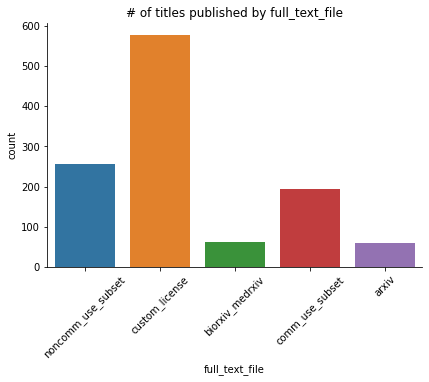

In [13]:
# plt.figure(figsize=(8, 5))
g = sns.catplot(x="full_text_file", kind="count", data=grouped_titles_by_time_source);
g.fig.set_figheight(4)
g.fig.set_figwidth(6)
plt.xticks(rotation=45)
plt.title('# of titles published by full_text_file')

Text(0.5, 1.0, '# of titles published over time')

<Figure size 1440x360 with 0 Axes>

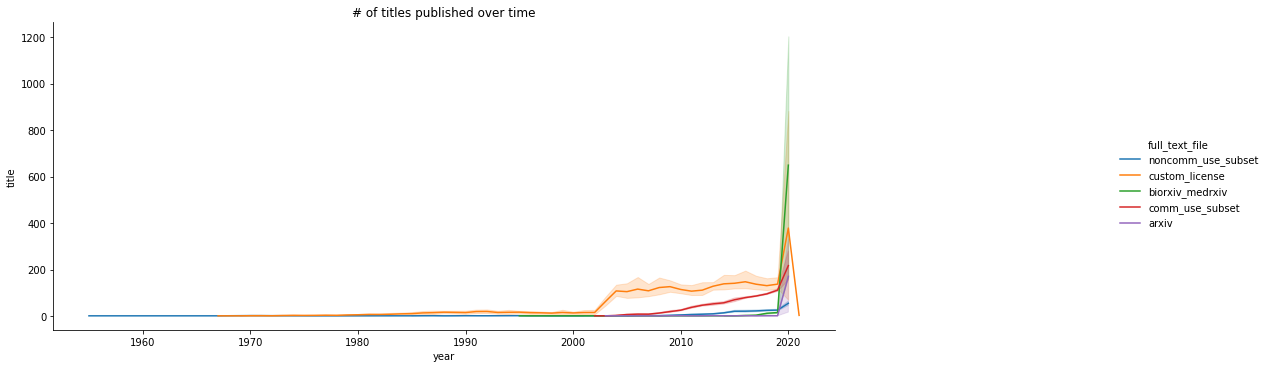

In [14]:
# # Summarize the number of publications
# groups_titles = df_titles.groupby(['year', 'month'])['title'].count()
# groups_titles = groups_titles.reset_index()
# groups_titles.tail()

plt.figure(figsize=(20, 5))
g = sns.relplot(x="year", y="title", kind="line", hue="full_text_file", dashes=False, markers=True, data=grouped_titles_by_time_source)
g.fig.set_figheight(5)
g.fig.set_figwidth(20)
plt.title('# of titles published over time')

# Extraction of author countries:

In [15]:
!pip install us

     |████████████████████████████████| 132 kB 4.1 MB/s 
  Created wheel for us: filename=us-2.0.2-py3-none-any.whl size=11927 sha256=f22373727edc31e30d70cd439fe658e8054fc221d106eef7bfb1821b433be03c
  Stored in directory: /root/.cache/pip/wheels/7c/41/9a/d0f0df54714732dfd740299373792cc1cf709e4b7fee8da12e
  Created wheel for jellyfish: filename=jellyfish-0.6.1-cp36-cp36m-linux_x86_64.whl size=81677 sha256=365f49f895042b3625d6bf8cf1755e9f12aef36482152966c9b7a46c55909f86
  Stored in directory: /root/.cache/pip/wheels/ca/7d/61/34766ffb4424b924a89158de5b9161bb42a75c663272d8c51e
Successfully built us jellyfish


In [16]:
# COUNTRIES_LOOKUP
[c.name for c in pycountry.subdivisions.get(country_code=pycountry.countries.get(name='Italy').alpha_2)]

NameError: name 'pycountry' is not defined

In [17]:
import pycountry     # package for all countries
import us # package for us states
from fuzzywuzzy import fuzz
from fuzzywuzzy import process

# countries lookup
COUNTRIES_LOOKUP = {c.name.lower():c.name for c in pycountry.countries}
CANADA_SUBDIVISIONS = [c.name for c in pycountry.subdivisions.get(country_code=pycountry.countries.get(name='Canada').alpha_2)]
INDIAN_STATES = [c.name for c in pycountry.subdivisions.get(country_code=pycountry.countries.get(name='India').alpha_2)]
JAPAN_SUBS = [c.name for c in pycountry.subdivisions.get(country_code=pycountry.countries.get(name='Japan').alpha_2)]
AUS_SUBS = [c.name for c in pycountry.subdivisions.get(country_code=pycountry.countries.get(name='Australia').alpha_2)]
CHINA_SUBS = [c.name for c in pycountry.subdivisions.get(country_code=pycountry.countries.get(name='China').alpha_2)]
ENG_SUBS = [c.name for c in pycountry.subdivisions.get(country_code=pycountry.countries.get(name='United Kingdom').alpha_2)]
COLOMBIA_SUBS = [c.name for c in pycountry.subdivisions.get(country_code=pycountry.countries.get(name='Colombia').alpha_2)]
ITALY_SUBS = [c.name for c in pycountry.subdivisions.get(country_code=pycountry.countries.get(name='Italy').alpha_2)]

# countries abbreviations lookup
CAN_ABR = [ c.code.replace(c.country_code+'-', '') for c in pycountry.subdivisions.get(country_code=pycountry.countries.get(name='Canada').alpha_2)]
AUS_ABR = [c.code.replace(c.country_code+'-', '') for c in pycountry.subdivisions.get(country_code=pycountry.countries.get(name='Australia').alpha_2)]

df_titles['countries'].replace('', "NA", inplace=True)

In [18]:
# import time

# country_counts = []
# for auth_coun in tqdm(df_titles["countries"].values):
#     country_counts.append(len([c for c in auth_coun.split(",")]))
# df_titles['country_counts'] = country_counts
# # print(df_titles['country_counts'].value_counts())

# start_time = time.time()
# author_coun_list = df_titles.loc[df_titles['country_counts'] >= 15]['countries'].values
# not_found_list = []
# for author_couns in tqdm(author_coun_list):
#     coun_list = author_couns.split(",")
#     for coun_raw in coun_list:
        
#         coun = re.sub('[^A-Za-z\s]+', '', coun_raw).strip()
#         us_state = us.states.lookup(coun)

#         if coun == "UK":
#             coun = "United Kingdom"
#         if coun == "Ont":
#             coun = "Ontario"
        
#         fuzzy_country = process.extractOne(coun.lower(), COUNTRIES_LOOKUP.keys(), scorer=fuzz.token_set_ratio) 
#         fuzzy_canada = process.extractOne(coun.lower(), CANADA_SUBDIVISIONS, scorer=fuzz.token_set_ratio) 
#         fuzzy_india = process.extractOne(coun.lower(), INDIAN_STATES, scorer=fuzz.token_set_ratio) 
#         fuzzy_japan = process.extractOne(coun.lower(), JAPAN_SUBS, scorer=fuzz.token_set_ratio) 
#         fuzzy_australia = process.extractOne(coun.lower(), AUS_SUBS, scorer=fuzz.token_set_ratio) 
#         fuzzy_china = process.extractOne(coun.lower(), CHINA_SUBS, scorer=fuzz.token_set_ratio) 
#         fuzzy_britain = process.extractOne(coun.lower(), ENG_SUBS, scorer=fuzz.token_set_ratio) 
#         fuzzy_colombia = process.extractOne(coun.lower(), COLOMBIA_SUBS, scorer=fuzz.token_set_ratio) 
#         fuzzy_espana_score = fuzz.token_sort_ratio(coun.lower(), "españa")
        
#         normalized_country = 'lookup_match_failed'
#         if us_state or coun.lower() == "usa" or coun.lower() == "united states":
#             normalized_country = "usa"
        
#         elif coun.lower() in COUNTRIES_LOOKUP:
#             normalized_country = coun.lower()
        
#         elif coun.lower() == 'russia':
#             normalized_country = 'russian federation'
        
#         elif coun.lower() == 'vietnam':
#             normalized_country = 'vietnam'
        
#         elif coun.lower() == 'south korea'
#             normalized_country = 'south korea'
        
#         elif coun.lower() == 'roc' or coun.lower() == 'pr china' or coun.lower() == 'prchina':
#             normalized_country = 'china'
        
#         elif fuzzy_espana_score >= 85 or coun.lower() == "sp":
#             normalized_country = 'spain'
        
#         elif coun in CAN_ABR or fuzzy_canada[1] >= 85:
#             normalized_country = 'canada'
# #             print(coun, "================= fuzzy_canada ===================>", normalized_country)
        
#         elif fuzzy_country[1] >= 85:
# #             print(coun, "================= fuzzy_country ===================>", fuzzy_country[0].lower())
#             normalized_country = fuzzy_country[0].lower()
        
#         elif fuzzy_india[1] >= 85:
# #             print(coun, "================= fuzzy_india ===================>", fuzzy_india[0].lower())
#             normalized_country = 'india'
        
#         elif fuzzy_japan[1] >= 85:
# #             print(coun, "================= fuzzy_japan ===================>", fuzzy_japan[0].lower())
#             normalized_country = 'japan'
        
#         elif coun in AUS_ABR or fuzzy_australia[1] >= 85:
#             normalized_country = 'australia'
# #             print(coun, "================= fuzzy_australia ===================>", normalized_country)
        
#         elif fuzzy_china[1] >= 85:
# #             print(coun, "================= fuzzy_china ===================>", fuzzy_china[0].lower())
#             normalized_country = 'china'
        
#         elif fuzzy_britain[1] >= 85:
# #             print(coun, "================= fuzzy_britain ===================>", fuzzy_britain[0].lower())
#             normalized_country = 'united kingdom'
        
#         elif fuzzy_colombia[1] >= 85:
# #             print(coun, "================= fuzzy_colombia ===================>", fuzzy_colombia[0].lower())
#             normalized_country = 'colombia'
    
#         elif fuzzy_italy[1] >= 85:
# #             print(coun, "================= fuzzy_italy ===================>", fuzzy_italy[0].lower())
#             normalized_country = 'italy'
    
# #         elif len(coun) > 3:
# #             try:
# #                 matches = pycountry.countries.search_fuzzy(coun)
# #                 if len(matches) > 0:
# #                     normalized_country = matches[0].name.lower()
# #             except:
# # #                 print(coun, "xxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxx")
# #                 not_found_list.append(coun)
    
#         else:
#             not_found_list.append(coun_raw)

#         normalized_country = "_".join(normalized_country.split(" "))
# #         print(coun, '=>', normalized_country)
# print('\n', len(set(not_found_list)), "countries not found...")
# print("time elapsed = ", time.time() - start_time, "for", len(author_coun_list), "rows")

In [19]:
not_found_list = []
titles_normalized_countries = []
count_countries = []

for auth_coun in tqdm(df_titles["countries"].values):
    coun_list = [c.strip() for c in auth_coun.split(",")]
    
    pub_normalized_countries = []
    for coun_raw in coun_list:    
        coun = re.sub('[^A-Za-z\s]+', '', coun_raw).strip()
        us_state = us.states.lookup(coun)

        if coun == "UK":
            coun = "United Kingdom"
        if coun == "Ont":
            coun = "Ontario"
        
        fuzzy_country = process.extractOne(coun.lower(), COUNTRIES_LOOKUP.keys(), scorer=fuzz.token_set_ratio) 
        fuzzy_canada = process.extractOne(coun.lower(), CANADA_SUBDIVISIONS, scorer=fuzz.token_set_ratio) 
        fuzzy_india = process.extractOne(coun.lower(), INDIAN_STATES, scorer=fuzz.token_set_ratio) 
        fuzzy_japan = process.extractOne(coun.lower(), JAPAN_SUBS, scorer=fuzz.token_set_ratio) 
        fuzzy_australia = process.extractOne(coun.lower(), AUS_SUBS, scorer=fuzz.token_set_ratio) 
        fuzzy_china = process.extractOne(coun.lower(), CHINA_SUBS, scorer=fuzz.token_set_ratio) 
        fuzzy_britain = process.extractOne(coun.lower(), ENG_SUBS, scorer=fuzz.token_set_ratio) 
        fuzzy_colombia = process.extractOne(coun.lower(), COLOMBIA_SUBS, scorer=fuzz.token_set_ratio) 
        fuzzy_italy = process.extractOne(coun.lower(), ITALY_SUBS, scorer=fuzz.token_set_ratio) 
        fuzzy_espana_score = fuzz.token_sort_ratio(coun.lower(), "españa")
        
        normalized_country = 'lookup_match_failed'
        if us_state or coun.lower() == "usa" or coun.lower() == "united states":
            normalized_country = "usa"
        
        elif coun.lower() in COUNTRIES_LOOKUP:
            normalized_country = coun.lower()
        
        elif coun.lower() == 'russia':
            normalized_country = 'russian federation'
        
        elif coun.lower() == 'vietnam':
            normalized_country = 'vietnam'
        
        elif coun.lower() == 'south korea':
            normalized_country = 'south korea'
        
        elif coun.lower() == 'roc' or coun.lower() == 'pr china' or coun.lower() == 'prchina':
            normalized_country = 'china'
        
        elif fuzzy_espana_score >= 85 or coun.lower() == "sp":
            normalized_country = 'spain'
        
        elif coun in CAN_ABR or fuzzy_canada[1] >= 85:
            normalized_country = 'canada'
#             print(coun, "================= fuzzy_canada ===================>", normalized_country)
        
        elif fuzzy_country[1] >= 85:
#             print(coun, "================= fuzzy_country ===================>", fuzzy_country[0].lower())
            normalized_country = fuzzy_country[0].lower()
        
        elif fuzzy_india[1] >= 85:
#             print(coun, "================= fuzzy_india ===================>", fuzzy_india[0].lower())
            normalized_country = 'india'
        
        elif fuzzy_japan[1] >= 85:
#             print(coun, "================= fuzzy_japan ===================>", fuzzy_japan[0].lower())
            normalized_country = 'japan'
        
        elif coun in AUS_ABR or fuzzy_australia[1] >= 85:
            normalized_country = 'australia'
#             print(coun, "================= fuzzy_australia ===================>", normalized_country)
        
        elif fuzzy_china[1] >= 85:
#             print(coun, "================= fuzzy_china ===================>", fuzzy_china[0].lower())
            normalized_country = 'china'
        
        elif fuzzy_britain[1] >= 85:
#             print(coun, "================= fuzzy_britain ===================>", fuzzy_britain[0].lower())
            normalized_country = 'united kingdom'
        
        elif fuzzy_colombia[1] >= 85:
#             print(coun, "================= fuzzy_colombia ===================>", fuzzy_colombia[0].lower())
            normalized_country = 'colombia'
        
        elif fuzzy_italy[1] >= 85:
#             print(coun, "================= fuzzy_italy ===================>", fuzzy_italy[0].lower())
            normalized_country = 'italy'
        
#         elif len(coun) > 3:
#             try:
#                 matches = pycountry.countries.search_fuzzy(coun)
#                 if len(matches) > 0:
#                     normalized_country = matches[0].name.lower()
#             except:
# #                 print(coun, "xxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxx")
#                 not_found_list.append(coun)
    
        else:
            not_found_list.append(coun_raw)

        normalized_country = "_".join(normalized_country.split(" "))
        pub_normalized_countries.append(normalized_country)
    
    titles_normalized_countries.append(pub_normalized_countries)
    count_countries.append(len(pub_normalized_countries))

print('\n', len(set(not_found_list)), "countries not found...")

100%|██████████| 56403/56403 [16:13<00:00, 57.94it/s]


 677 countries not found...


**Countries that were not found from look up:**

In [20]:
# Tally occurrences of words in a list
from collections import Counter

# print(len(set(not_found_list)))

cnt = Counter()
for word in not_found_list:
    cnt[word] += 1
# cnt
sorted(cnt.items(), key=lambda item: item[1], reverse=True)

[('NA', 36230),
 ('Czech Republic', 46),
 ('RJ', 22),
 ('CP', 18),
 ('UK A R', 18),
 ('CEP', 18),
 ('Oxford', 17),
 ('MG', 16),
 ('EA', 15),
 ('Vic', 15),
 ('Guangdong Province', 15),
 ('RN', 14),
 ('Winnipeg', 14),
 ('MC', 14),
 ('Qld', 14),
 ('RS', 12),
 ('NIH', 12),
 ('Korea Research', 12),
 ('', 11),
 ('DF', 11),
 ('US', 9),
 ('CS', 9),
 ('NW', 9),
 ('Nuevo León', 8),
 ('Taipei', 8),
 ('Mumbai', 8),
 ('PD', 8),
 ('Sask', 8),
 ('BA', 7),
 ('Wuhan', 7),
 ('Jiangsu Province', 7),
 ('CNRS', 7),
 ('Srinagar', 7),
 ('F.R.G', 7),
 ('Taiwan University', 6),
 ('D.C.L.)', 6),
 ('H.Y.', 6),
 ('K.B.H.', 6),
 ('K.M.V.', 6),
 ('K.K.O.', 6),
 ('P.M.', 6),
 ('S.F.T.)', 6),
 ('Middlesex', 6),
 ('Queen', 6),
 ('China-Japan', 6),
 ('UMR', 6),
 ('IRD', 6),
 ('Co. Cork', 6),
 ('Que', 6),
 ('email', 5),
 ('Tex', 5),
 ('E.N.P.)', 5),
 ('Medicine (S.Y.L.', 5),
 ('C.L.S.', 5),
 ('G.M.S.)', 5),
 ('and Pathology (J.K.J.)', 5),
 ('Allergy', 5),
 ('No', 5),
 ('Selangor', 5),
 ('Valencia', 5),
 ('SE', 5),
 ('AP

**Add the extracted normalized author countries back to titles data frame:**

In [21]:
df_titles['normalized_countries_count'] = count_countries
df_titles['normalized_countries'] = [' '.join(list(set(c))) for c in titles_normalized_countries]
df_titles['normalized_countries'].value_counts()

lookup_match_failed                            36634
usa                                             6013
china                                           2274
united_kingdom                                   837
canada                                           617
                                               ...  
nigeria lookup_match_failed                        1
congo                                              1
usa colombia                                       1
sweden united_kingdom finland australia usa        1
lookup_match_failed usa sweden                     1
Name: normalized_countries, Length: 1130, dtype: int64

**Compute the Bag-Of_words for the extracted countries using CountVectorizer:**

In [22]:
df_titles['cord_uid'].head(5)

0      zjufx4fo
33     ymceytj3
68     wzj2glte
96     2sfqsfm1
127    i0zym7iq
Name: cord_uid, dtype: object

In [23]:
from sklearn.feature_extraction.text import CountVectorizer

# create a dataframe from a word matrix
def wm2df(wm, feat_names, cord_uids):
    
    # create an index for each row
#     doc_names = ['Pub{:d}'.format(idx) for idx, _ in enumerate(wm)]
    df = pd.DataFrame(data=wm.toarray(), index=cord_uids,
                      columns=feat_names)
    return(df)
  
# set of documents
corpora = [' '.join(list(set(c))) for c in titles_normalized_countries]

# instantiate the vectorizer object
cvec = CountVectorizer(lowercase=False, min_df=50)

# convert the documents into a document-term matrix
wm = cvec.fit_transform(corpora)

# retrieve the terms found in the corpora
tokens = cvec.get_feature_names()

# create a dataframe from the matrix
df_country_vectors = wm2df(wm, tokens, df_titles['cord_uid'].values)
df_country_vectors.head()

,_islamic_republic_of,_province_of_china,_republic_of,argentina,australia,austria,belgium,brazil,canada,china,...,south_africa,south_korea,spain,sweden,switzerland,taiwan,thailand,turkey,united_kingdom,usa
zjufx4fo,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
ymceytj3,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
wzj2glte,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
2sfqsfm1,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
i0zym7iq,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0


In [24]:
df_country_vectors.ix['i0zym7iq']

/opt/conda/lib/python3.6/site-packages/ipykernel_launcher.py:1: FutureWarning: 
.ix is deprecated. Please use
.loc for label based indexing or
.iloc for positional indexing

See the documentation here:
http://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#ix-indexer-is-deprecated
  """Entry point for launching an IPython kernel.


_islamic_republic_of    0
_province_of_china      0
_republic_of            0
argentina               0
australia               0
austria                 0
belgium                 0
brazil                  0
canada                  0
china                   0
colombia                0
denmark                 0
egypt                   0
finland                 0
france                  0
germany                 0
greece                  0
india                   0
iran                    0
ireland                 0
israel                  0
italy                   0
japan                   0
jordan                  0
korea                   0
lookup_match_failed     1
malaysia                0
netherlands             0
new_zealand             0
norway                  0
pakistan                0
poland                  0
portugal                0
russian_federation      0
saudi_arabia            0
singapore               0
south_africa            0
south_korea             0
spain       

# Visualizing research in different countries on epidemics and pandemics:

In [25]:
import seaborn as sns
import matplotlib.pylab as plt
%matplotlib inline

no_of_pubs_by_country = df_country_vectors.sum()
no_of_pubs_by_country.sort_values(ascending=False, inplace=True)
no_of_pubs_by_country = no_of_pubs_by_country.drop(labels=['lookup_match_failed'])
no_of_pubs_by_country = no_of_pubs_by_country.head(17)

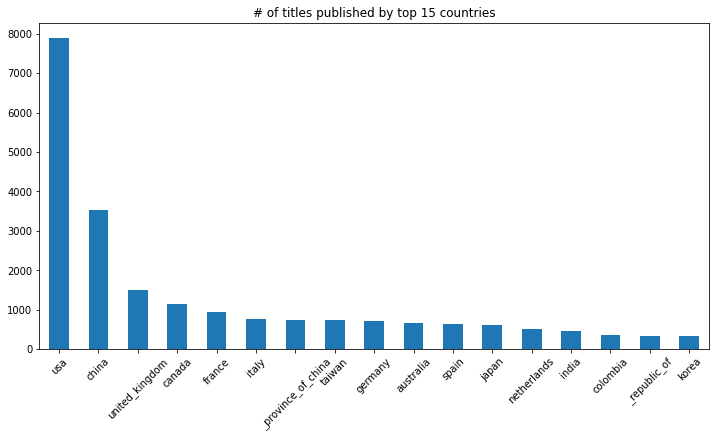

In [26]:
ax = no_of_pubs_by_country.plot.bar(figsize=(12, 6), rot=45, title='# of titles published by top 15 countries')

/opt/conda/lib/python3.6/site-packages/ipykernel_launcher.py:12: FutureWarning: 
.ix is deprecated. Please use
.loc for label based indexing or
.iloc for positional indexing

See the documentation here:
http://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#ix-indexer-is-deprecated
  if sys.path[0] == '':
/opt/conda/lib/python3.6/site-packages/pandas/plotting/_matplotlib/core.py:575: UserWarning: The handle <matplotlib.lines.Line2D object at 0x7f99f3e26208> has a label of '_province_of_china' which cannot be automatically added to the legend.
  ax.legend(handles, labels, loc="best", title=title)
/opt/conda/lib/python3.6/site-packages/pandas/plotting/_matplotlib/core.py:575: UserWarning: The handle <matplotlib.lines.Line2D object at 0x7f99f3e3f1d0> has a label of '_republic_of' which cannot be automatically added to the legend.
  ax.legend(handles, labels, loc="best", title=title)


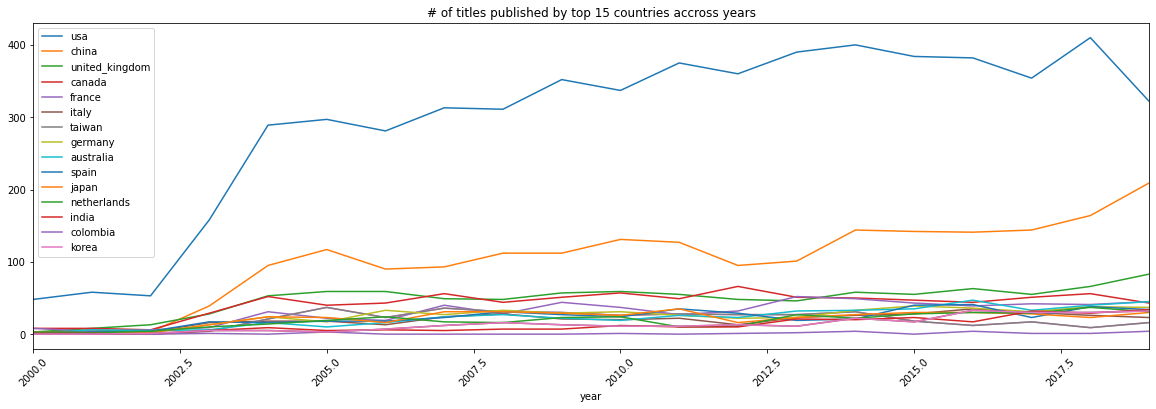

In [27]:
df_country_vectors["publish_date"] = df_titles["publish_date"].values
df_country_vectors['month'] = df_country_vectors["publish_date"].dt.month
df_country_vectors['year'] = df_country_vectors["publish_date"].dt.year

top_author_countries = list(no_of_pubs_by_country.index.values)
# top_author_countries.remove('year')
# top_author_countries.remove('month')

year_wise = df_country_vectors.groupby(['year']).sum()
year_wise = year_wise[top_author_countries]

year_wise = year_wise.ix[[2000.0, 2001.0, 2002.0, 2003.0, 2004.0,
              2005.0, 2006.0, 2007.0, 2008.0, 2009.0, 2010.0, 2011.0, 2012.0,
              2013.0, 2014.0, 2015.0, 2016.0, 2017.0, 2018.0, 2019.0
]]
year_wise
year_wise.plot(figsize=(20, 6), rot=45, title='# of titles published by top 15 countries accross years')

**In the above plot we can see USA easily leads the race in research. It has particularly picked up around 2003, which was the first SARs outbreak.**

/opt/conda/lib/python3.6/site-packages/ipykernel_launcher.py:16: FutureWarning: 
.ix is deprecated. Please use
.loc for label based indexing or
.iloc for positional indexing

See the documentation here:
http://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#ix-indexer-is-deprecated
  app.launch_new_instance()


([<matplotlib.axis.XTick at 0x7f99f3d7bd68>,
 [Text(0, 0, 'usa'),
  Text(0, 0, 'china'),
  Text(0, 0, 'united_kingdom'),
  Text(0, 0, 'canada'),
  Text(0, 0, 'france'),
  Text(0, 0, 'italy'),
  Text(0, 0, '_province_of_china'),
  Text(0, 0, 'taiwan'),
  Text(0, 0, 'germany'),
  Text(0, 0, 'australia'),
  Text(0, 0, 'spain'),
  Text(0, 0, 'japan'),
  Text(0, 0, 'netherlands'),
  Text(0, 0, 'india'),
  Text(0, 0, 'colombia'),
  Text(0, 0, '_republic_of'),
  Text(0, 0, 'korea')])

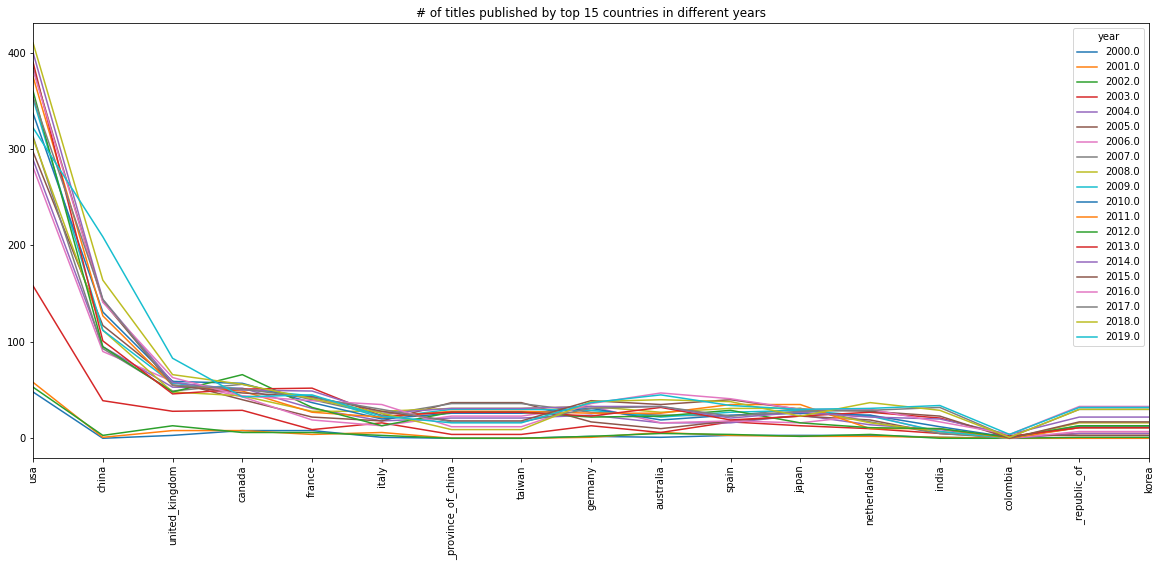

In [28]:
df_country_vectors["publish_date"] = df_titles["publish_date"].values
df_country_vectors['month'] = df_country_vectors["publish_date"].dt.month
df_country_vectors['year'] = df_country_vectors["publish_date"].dt.year

year_wise = df_country_vectors.groupby(['year']).sum()
coun_wise = year_wise.T
coun_wise = coun_wise[[2000.0, 2001.0, 2002.0, 2003.0, 2004.0,
              2005.0, 2006.0, 2007.0, 2008.0, 2009.0, 2010.0, 2011.0, 2012.0,
              2013.0, 2014.0, 2015.0, 2016.0, 2017.0, 2018.0, 2019.0
]]
top_author_countries = list(no_of_pubs_by_country.index.values)
# top_author_countries.remove('year')
# top_author_countries.remove('month')
# top_author_countries.remove('usa')

coun_wise = coun_wise.ix[top_author_countries]
coun_wise.plot(figsize=(20, 8), rot=90, title='# of titles published by top 15 countries in different years')
plt.xticks(range(0,len(coun_wise.index)), top_author_countries, rotation=90)

**The above plot again tries to show the RELATIVE research done by different countries in the twentieth century. We have dropped the USA since it becomes difficult to visualize the other countries!**

In [29]:
# df_country_vectors.index = df_titles["publish_date"].values
# df_country_vectors = df_country_vectors.cumsum()
# # df_country_vectors.head()
# # df_country_vectors[['united_kingdom', 'italy']].plot(subplots=True, figsize=(6, 6)); plt.legend(loc='best')

# fig, axes = plt.subplots(nrows=2, ncols=2)

# df_country_vectors['united_kingdom'].plot(ax=axes[0,0]); axes[0,0].set_title('united_kingdom')
# df_country_vectors['italy'].plot(ax=axes[0,1]); axes[0,1].set_title('italy')
# df_country_vectors['usa'].plot(ax=axes[1,0]); axes[1,0].set_title('usa')
# df_country_vectors['china'].plot(ax=axes[1,1]); axes[1,1].set_title('china')


# # df_country_vectors[['united_kingdom', 'italy']].plot.box()

In [30]:
# plt.figure(figsize=(20, 5))
# # g = sns.relplot(x="year", y="china", kind="line", data=coun_grps_titles)
# g = sns.lineplot(data=coun_grps_titles)
# g.fig.set_figheight(5)
# g.fig.set_figwidth(20)
# plt.title('# of titles published over time')

# g = coun_grps_titles[['year', 'united_kingdom', 'italy']].plot(x="year", figsize=(20, 5), title='# of titles published over time for countries')

In [31]:
import gc
gc.collect()

0

**Load FastText sent2vec model trained on CORD-19 corpus**

In [32]:
import sent2vec
#model_path = "/kaggle/input/biosentvec/BioSentVec_CORD19-bigram_d700.bin"
model_path = "/kaggle/input/covid-sent2vec-ver2/BioSentVec_CORD19-bigram_d700_v2.bin"
model = sent2vec.Sent2vecModel()
try:
    model.load_model(model_path)
except Exception as e:
    print(e)
print("model successfully loaded")

model successfully loaded


# Sub-task Queries

In [33]:
# Vaccines
sub_tasks = [
    "What do we know about vaccines and therapeutics for COVID 19 or the novel coronavirus? What has been published concerning research and development and evaluation efforts of vaccines and therapeutics for COVID 19 or the novel coronavirus?",
    "What is the effectiveness of drugs being developed and tried (like chloroquine, arbidol, remdesivir, and favipiravir) to treat COVID-19 patients.",
    "Clinical and bench trials to investigate less common viral inhibitors against COVID-19 such as naproxen, clarithromycin, and minocyclinethat that may exert effects on viral replication.",
    "Methods evaluating potential complication of Antibody-Dependent Enhancement (ADE) in vaccine recipients for COVID 19 or the novel coronavirus.",
    "Exploration of use of best animal models and their predictive value for a human vaccine.",
    "Capabilities to discover a therapeutic for COVID 19 or the novel coronavirus, and clinical effectiveness studies to discover therapeutics, to include antiviral agents.",
    "Alternative models to aid decision makers in determining how to prioritize and distribute scarce, newly proven therapeutics as production ramps up for COVID 19 or the novel coronavirus. This could include identifying approaches for expanding production capacity to ensure equitable and timely distribution to populations in need.",
    "Efforts targeted at a universal coronavirus vaccine.",
    "Efforts to develop animal models and standardize challenge studies for COVID 19 or the novel coronavirus",
    "Efforts to develop prophylaxis clinical studies and prioritize in healthcare workers for COVID 19 or the novel coronavirus",
    "Approaches to evaluate risk for enhanced disease after vaccination for COVID 19 or the novel coronavirus",
    "Assays to evaluate vaccine immune response and process development for vaccines, alongside suitable animal models in conjunction with therapeutics for COVID 19 or the novel coronavirus"
]
sub_tasks_names = [
    "summary",
    "drugs_efficacy",
    "bench_trials",
    "complication_ade",
    "exploration_animal_models",
    "therapeutics_efficacy",
    "alternative_models",
    "universal_coronavirus_vaccine.",
    "develop_animal_models",
    "prophylaxis_clinical_studies",
    "risk_post_vaccination",
    "vaccine_immune_response"
]

# Abstract embeddings & Plots:

**Let's analyze the available abstracts with respect to the queries for this Task:**

In [34]:
from scipy.spatial import distance

def create_abstract_task_embeddings():
    abstract_vectors = []
    paper_cord_uids = []
    for cord_uid, abstract in tqdm(df_abstracts[["cord_uid","paragraph"]].values):
        if not isinstance(abstract, str):
            continue

        sub_tasks_vectors = []
        for sub_task in sub_tasks:
            # prepare the individual vectors of paragraphs
            embs = model.embed_sentences([abstract, sub_task])
            cosine_sim = 1 - distance.cosine(embs[0], embs[1])
            sub_tasks_vectors.append(cosine_sim)

        # compute the max of vectors to get paper vectors
        abstract_vectors.append(sub_tasks_vectors)
        paper_cord_uids.append(cord_uid)

    # store the paper vector into df
    print(len(abstract_vectors), len(df_abstracts))
    df_abstracts_vectors = pd.DataFrame(abstract_vectors, columns=sub_tasks_names)
    
    return df_abstracts_vectors

df_abstracts_vectors = create_abstract_task_embeddings()


  2%|▏         | 717/47061 [00:04<04:53, 157.66it/s]/opt/conda/lib/python3.6/site-packages/scipy/spatial/distance.py:720: RuntimeWarning: invalid value encountered in float_scalars
  dist = 1.0 - uv / np.sqrt(uu * vv)
100%|██████████| 47061/47061 [04:41<00:00, 166.99it/s]


47061 47061


In [35]:
df_abstracts_vectors.describe()

,summary,drugs_efficacy,bench_trials,complication_ade,exploration_animal_models,therapeutics_efficacy,alternative_models,universal_coronavirus_vaccine.,develop_animal_models,prophylaxis_clinical_studies,risk_post_vaccination,vaccine_immune_response
count,47056.000000,47056.000000,47056.000000,47056.000000,47056.000000,47056.000000,47056.000000,47056.000000,47056.000000,47056.000000,47056.000000,47056.000000
mean,0.507815,0.448090,0.488125,0.491990,0.468986,0.490046,0.559906,0.314208,0.504075,0.534565,0.418658,0.513764
std,0.091083,0.097990,0.080292,0.076499,0.084216,0.084391,0.096347,0.070579,0.079778,0.093868,0.084925,0.082237
min,-0.126789,-0.055397,-0.126984,-0.199877,-0.096686,-0.141938,-0.117718,-0.125484,-0.145829,-0.138453,-0.143883,-0.178093
25%,0.448608,0.385024,0.442585,0.446736,0.421356,0.440315,0.497091,0.269146,0.458614,0.473457,0.363219,0.467811
50%,0.507453,0.451537,0.490475,0.498112,0.476759,0.493963,0.560103,0.315194,0.509940,0.540873,0.425815,0.516892
75%,0.569934,0.518375,0.537795,0.544221,0.526355,0.546640,0.628040,0.360410,0.557399,0.603505,0.479057,0.565437
max,0.784172,0.772625,0.766884,0.738676,0.748027,0.768680,0.845452,0.612906,0.757544,0.803612,0.699521,0.782721


**The sentence embeddings extracted for available abstracts in metadata.csv are compared with the several smaller questions around this particular tasks. The following box plot shows the match of the literature around these questions, kind off measuring the confidence levels of the answers: **

Some insights from the plot:
* **universal_coronavirus_vaccine** has the lowest mean confidence. 
    This means that for the question *"Efforts targeted at a universal coronavirus vaccine."* the answers may not be too relevant
* **alternative_models** has the highest mean confidence.
    This means that for the question *"Alternative models to aid decision makers in determining how to prioritize and distribute scarce, newly proven therapeutics as production ramps up for COVID 19 or the novel coronavirus. This could include identifying approaches for expanding production capacity to ensure equitable and timely distribution to populations in need."* the answers will hopefully be more relevant

(array([ 0,  1,  2,  3,  4,  5,  6,  7,  8,  9, 10, 11]),
 <a list of 12 Text major ticklabel objects>)

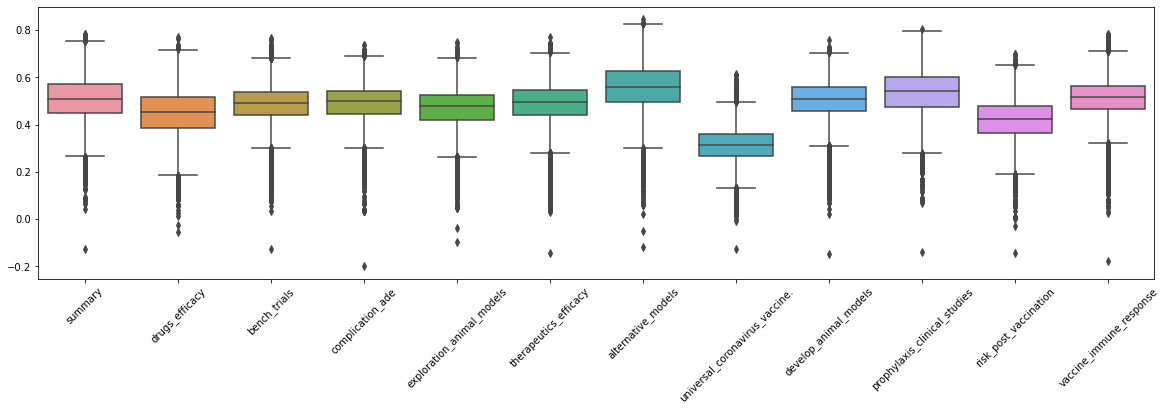

In [36]:
plt.figure(figsize=(20, 5))
sns.boxplot(data=df_abstracts_vectors)
plt.xticks(rotation=45)

In [37]:
df_rounded = df_abstracts_vectors.round(0).astype(pd.Int32Dtype())
df_rounded["date"] = df_abstracts.publish_date.values
df_rounded['month'] = df_rounded["date"].dt.month
df_rounded['year'] = df_rounded["date"].dt.year

# Summarize the number of publications
groups_abs_vects = df_rounded.groupby(['year', 'month']).sum()
groups_abs_vects = groups_abs_vects.reset_index()

**Let's look at the number of published titles on "Efforts targeted at a universal coronavirus vaccine" with time:**

Text(0.5, 1.0, '# of publications on "Efforts targeted at a universal coronavirus vaccine" over time')

<Figure size 1440x360 with 0 Axes>

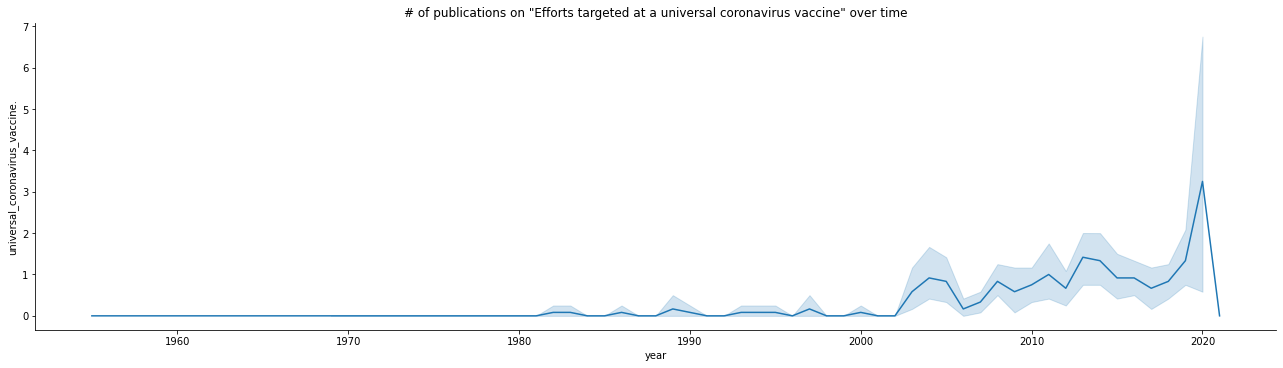

In [38]:
plt.figure(figsize=(20, 5))
g = sns.relplot(x="year", y="universal_coronavirus_vaccine.", kind="line", data=groups_abs_vects)
g.fig.set_figheight(5)
g.fig.set_figwidth(20)
plt.title('# of publications on "Efforts targeted at a universal coronavirus vaccine" over time')

**We can note that there have been spurts in the research with time.**

**Now let's look at the number of published titles on "Alternative models to prioritize and distribute scarce, newly proven therapeutics" with time:**

Text(0.5, 1.0, '# of publications on "Alternative models to prioritize and distribute scarce, newly proven therapeutics" over time')

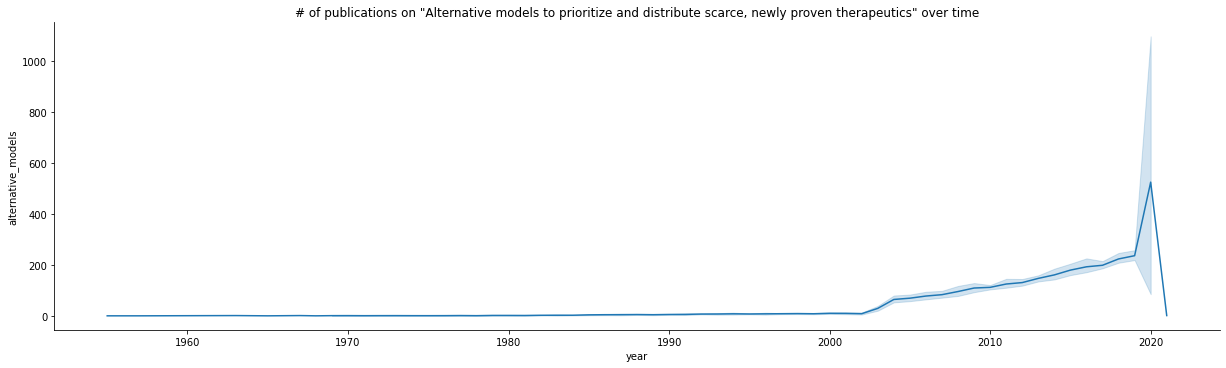

In [39]:
g = sns.relplot(x="year", y="alternative_models", kind="line", data=groups_abs_vects)
g.fig.set_figheight(5)
g.fig.set_figwidth(20)
plt.title('# of publications on "Alternative models to prioritize and distribute scarce, newly proven therapeutics" over time')

**We can note that there has been special interest after the occurence of the first outbreak of SARS in early 2000 and thereafter number of published titles have increased considerably**

In [40]:
def display_time_plots(sub_task_name):
    plt.figure(figsize=(20, 5))
    g = sns.relplot(x="year", y=sub_task_name, kind="line", data=groups_abs_vects);
    g.fig.set_figheight(5)
    g.fig.set_figwidth(20)
    plt.title('# of publications over time')

In [41]:
# # df_abstracts_indexed = df_abstracts.set_index(df_abstracts.publish_date)
# df_tsplot = df_abstracts_vectors.copy()
# # df_tsplot["date"] = df_abstracts.publish_date

# plt.figure(figsize=(20,8))

# # This plot shows the confidence level of the match between each sub_task and related content
# g = sns.boxplot(data=df_tsplot)
# plt.xticks(rotation=45)
# # g = sns.pairplot(df_tsplot)

# # g = sns.relplot(x="date", y="summary", kind="line", data=df_tsplot)

# # def display_correlation_plots_abstracts():
    
# #     corr = df_abstracts_vectors.corr()
# #     ax = sns.heatmap(
# #         corr, 
# #         vmin=-1, vmax=1, center=0,
# #         cmap=sns.diverging_palette(20, 220, n=200),
# #         square=True
# #     )
# #     ax.set_xticklabels(
# #         ax.get_xticklabels(),
# #         rotation=45,
# #         horizontalalignment='right'
# #     );

# #     g = sns.pairplot(corr)

# Title embeddings & Plots:

In [42]:
def generate_title_embeddings():
    title_dict = {}
    titles_list = []
    title_covid_tags = []
    for cord_uid, title in tqdm(df_titles[["cord_uid","title"]].values):
        if isinstance(title, str):
            title_dict[cord_uid] = model.embed_sentence(title)
            titles_list.append(title)
            title_covid_tags.append(covid_tags(title))

    paper_ids = list(title_dict.keys())
    t_vectors = np.array(list(title_dict.values()))
    nsamples, x, y = t_vectors.shape
    titles_array = t_vectors.reshape((nsamples,x*y))
    print(titles_array.shape)
    
#     print("Computing cosine similarity matrix.....")
#     cosine_sim_matrix = cosine_similarity(titles_array, titles_array)
    
#     n_sim_articles = 3
#     input_idx = 1

#     sim_indexes = np.argsort(cosine_sim_matrix[input_idx])[::-1][1:n_sim_articles+1]
#     print("sim_indexes", sim_indexes)

#     print("-------QUERY TITLE-----")
#     print(titles_list[input_idx])
#     print()
#     print(f"----TOP {n_sim_articles} SIMILAR TITLES-----")
#     for sim_idx in sim_indexes:
#         print(titles_list[sim_idx])
#         print()
#         print("-"*50)
    
    
    return paper_ids, titles_array, titles_list, title_covid_tags

paper_ids, titles_array, titles_list, title_covid_tags = generate_title_embeddings()

100%|██████████| 56403/56403 [00:09<00:00, 5645.90it/s]


(56395, 700)


# Sub-task wise document clusters & statistics (by license, author location, date, Title word cloud):

In [43]:
def summarize_paragraph(para_text):
    doc = medical(para_text)
    
    entities_list = []
    sent_dict = {}
    sent_list = []
    for sent in doc.sents:
        sent_dict[sent.text] = model.embed_sentence(sent.text)
        sent_list.append(sent.text)
        entities_list.extend([ent.text for ent in doc.ents])

    s_vectors = np.array(list(sent_dict.values()))
    nsamples, x, y = s_vectors.shape
    sent_vectors = s_vectors.reshape((nsamples,x*y))
    cosine_sim_matrix_sents = cosine_similarity(sent_vectors, query_vector.reshape(1,-1))

    if len(sent_list) > 30:
        no_of_sents_summ = int(len(sent_list) * 0.1)
    elif len(sent_list) > 20:
        no_of_sents_summ = int(len(sent_list) * 0.2)
    elif len(sent_list) > 10:
        no_of_sents_summ = int(len(sent_list) * 0.3)
    elif len(sent_list) > 5:
        no_of_sents_summ = int(len(sent_list) * 0.4)
    else:
        no_of_sents_summ = len(sent_list)

    sent_sim_indexes = np.argsort(cosine_sim_matrix_sents.reshape(1,-1)[0])[::-1][:no_of_sents_summ]
    sents_summ = [sent_list[j] for j in sent_sim_indexes]
    return " ".join(sents_summ), entities_list

In [44]:
pd.set_option('display.max_columns', None)
pd.set_option('display.max_colwidth', -1)

def get_documents_clusters_by_titles(query_statement, no_of_docs=30):
    is_COVID = covid_tags(query_statement)
    
    display(Markdown("# Query : "+query_statement))
    
    # extract the cosine similarity of query against titles
    title_sim_matrix_query = cosine_similarity(titles_array, query_vector.reshape(1,-1))
    titles_similarities = title_sim_matrix_query.reshape(1,-1)[0]*100
    
    df_publications = pd.DataFrame(list(zip(paper_ids, titles_list, titles_similarities, title_covid_tags)), 
               columns =['cord_uid', 'title', 'title_similarity', 'tag'])
    df_publications = df_publications.sort_values(by='title_similarity', ascending=False)
    
    if is_COVID == 'COVID-19':
        df_publications = df_publications.loc[df_publications['tag'] == 'COVID-19']
    
    if df_publications['title_similarity'].max() > 80:
        df_shortlisted = df_publications.loc[df_publications['title_similarity'] >= 65]
    elif df_publications['title_similarity'].max() > 75:
        df_shortlisted = df_publications.loc[df_publications['title_similarity'] >= 60]
    elif df_publications['title_similarity'].max() > 70:
        df_shortlisted = df_publications.loc[df_publications['title_similarity'] >= 55]
    else:
        df_shortlisted = df_publications.loc[df_publications['title_similarity'] >= 50]
    
    display(Markdown("Selected top "+ str(len(df_shortlisted)) + " publications"))
#     display(df_shortlisted[['paper_id', 'title', 'title_similarity']])
    
    return df_shortlisted['cord_uid'].values

In [45]:
def get_documents_clusters_by_titles_n_abstracts(query_statement, no_of_docs=30):
    is_COVID = covid_tags(query_statement)
    
    display(Markdown("**Query : "+query_statement+"**"))
    
    # extract the cosine similarity of query against abstracts
    abstract_sim_matrix_query = cosine_similarity(values_array, query_vector.reshape(1,-1))
    abstracts_similarities = abstract_sim_matrix_query.reshape(1,-1)[0]*100
    
    # extract the cosine similarity of query against titles
    title_sim_matrix_query = cosine_similarity(titles_array, query_vector.reshape(1,-1))
    titles_similarities = title_sim_matrix_query.reshape(1,-1)[0]*100
    
    df_shortlisted = pd.DataFrame(list(zip(paper_ids, titles_list, titles_similarities, abstracts_list, 
                                           abstracts_similarities, title_covid_tags)), 
               columns =['paper_id', 'title', 'title_similarity', 'abstract', 'abstract_similarity', 'tag'])
    df_shortlisted = df_shortlisted.sort_values(['title_similarity', 'abstract_similarity'], ascending=(False, False))
    
    if is_COVID == 'COVID-19':
        df_shortlisted = df_shortlisted.loc[df_shortlisted['tag'] == 'COVID-19']
    
    df_shortlisted["Relevance"] = (df_shortlisted['title_similarity']+df_shortlisted['abstract_similarity'])/2
    df_shortlisted = df_shortlisted.sort_values(by='Relevance', ascending=False)
    df_shortlisted = df_shortlisted.loc[df_shortlisted['Relevance'] >= 45]
    display(Markdown(str(len(df_shortlisted)) + " publications shortlisted. Selecting top 30:"))
    df_shortlisted = df_shortlisted.head(no_of_docs)
    
    shortlisted_abstracts = df_shortlisted["abstract"].values
    abs_summ = []
    for para in shortlisted_abstracts:
        abs_summ.append(summarize_paragraph(para))
    
    df_shortlisted["abs_summary"] = abs_summ
    
    display(df_shortlisted[['Relevance','title', 'title_similarity', 'abs_summary', 'abstract_similarity']])
    return df_shortlisted['paper_id'].values

# Sub-task wise paragraph clusters, pre-processing & medical NER extraction, histograms:

In [46]:
from wordcloud import WordCloud, STOPWORDS, ImageColorGenerator

stopwords = set(STOPWORDS)
stopwords.update(["SARS", "COVID", "et al", "patient", "will", 'may'])

def depict_word_cloud(paragraphs, query_name):
    text = " ".join(paragraphs)
    
    wordcloud = WordCloud(stopwords=stopwords, width = 3600, height = 2400, min_font_size = 10, 
                          background_color="white").generate(text)
    
    # Display the generated image:
    plt.figure(figsize=(15,10))
    plt.imshow(wordcloud, interpolation='bilinear')
    plt.axis("off")
    plt.show()
    
    wordcloud.to_file("/kaggle/working/"+ query_name +"_wordcloud.png")

In [47]:
def get_paragraphs_cluster(sub_task, paper_ids, no_of_paras=10):
    is_COVID = covid_tags(sub_task)

    df_paragraphs = pd.DataFrame()
    body_para_list = []
    for paper_id in paper_ids:
        try:
            body = paper_bodies.get_group(paper_id)
        except:
            continue
        body["section_id"] = (pd.RangeIndex(stop=body.shape[0])+1)/len(body)*100
        df_paragraphs = df_paragraphs.append(body, ignore_index = True) 
        body_para_list.extend(body["paragraph"].values)
    
    para_dict = {}
    para_list = []
    para_covid_tags = []
    p = 0
    for para in body_para_list:
        para_dict[p] = model.embed_sentence(para)
        para_list.append(para)
        para_covid_tags.append(covid_tags(para))
        p += 1

    # Para level vectors
    p_vectors = np.array(list(para_dict.values()))
    nsamples, x, y = p_vectors.shape
    para_vectors = p_vectors.reshape((nsamples,x*y))

    para_matrix_query = cosine_similarity(para_vectors, query_vector.reshape(1,-1))
    para_similarities_array = para_matrix_query.reshape(1,-1)[0]
    
    df_paragraphs['tag'] = para_covid_tags
    df_paragraphs["para_similarity"] = para_similarities_array*100
    
    if is_COVID == 'COVID-19':
        df_paragraphs = df_paragraphs.loc[df_paragraphs['tag'] == 'COVID-19']
    
#     df_paragraphs = df_paragraphs.loc[df_paragraphs['para_similarity'] >= 50]
#     df_paragraphs["Relevance"] = (2*df_paragraphs['para_similarity']+df_paragraphs['section_id'])/3
    
    df_paragraphs = df_paragraphs.sort_values(by=['para_similarity', 'publish_date'], ascending=(False, False))
    
    if len(df_paragraphs) > 15:
        df_paragraphs = df_paragraphs.head(15)
    
    display(Markdown(str(len(df_paragraphs)) + " paragraphs shortlisted."))
#     display(df_paragraphs[['publish_date', 'title', 'paragraph', 'para_similarity']])
    return df_paragraphs

In [48]:
def comprehend_paragraph(para_text):
    doc = medical(para_text)
        
    sent_dict = {}
    sent_list = []
    for sent in doc.sents:
        sent_dict[sent.text] = model.embed_sentence(sent.text)
        sent_list.append(sent.text)

    s_vectors = np.array(list(sent_dict.values()))
    nsamples, x, y = s_vectors.shape
    sent_vectors = s_vectors.reshape((nsamples,x*y))
    sent_sim_matrix_sents = cosine_similarity(sent_vectors, query_vector.reshape(1,-1))
    sents_similarities = sent_sim_matrix_sents.reshape(1,-1)[0]*100
    
    df_sents = pd.DataFrame(list(zip(sent_list, sents_similarities)), columns =['sentence', 'similarity'])
    df_sents = df_sents.sort_values(by='similarity', ascending=False)
    df_sents = df_sents.loc[df_sents['similarity']>50]
    
    return ' '.join(df_sents['sentence'].values), df_sents['similarity'].max()

# Query : What do we know about vaccines and therapeutics for COVID 19 or the novel coronavirus? What has been published concerning research and development and evaluation efforts of vaccines and therapeutics for COVID 19 or the novel coronavirus?

Selected top 302 publications

15 paragraphs shortlisted.

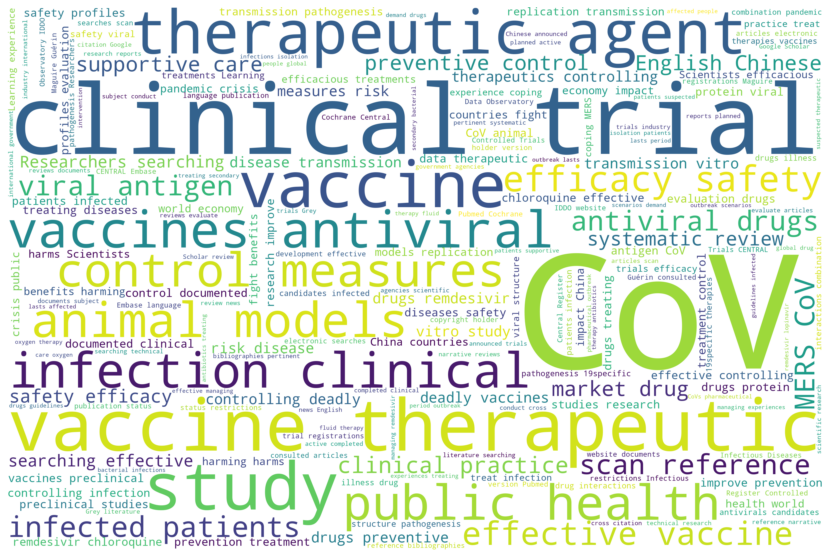

**Query : What do we know about vaccines and therapeutics for COVID 19 or the novel coronavirus? What has been published concerning research and development and evaluation efforts of vaccines and therapeutics for COVID 19 or the novel coronavirus?**

***Individual risk management strategy and potential therapeutic options for the COVID-19 pandemic (2020.04.07):***

> Several companies and research groups initiate the development of potential vaccines for COVID-19.**

,publish_date,title,para_summary,para_similarity
517,2020-04-07,Individual risk management strategy and potential therapeutic options for the COVID-19 pandemic,Several companies and research groups initiate the development of potential vaccines for COVID-19.,78.688515
271,2020-03-18,"COVID-19, an emerging coronavirus infection: advances and prospects in designing and developing vaccines, immunotherapeutics, and therapeutics","Achievements in the development of vaccines and therapeutic agents for SARS- and MERS-CoV as well as recent ongoing progress for COVID-19 will facilitate the development of effective vaccines and therapeutics against this emerging virus. However, the present scenario of COVID-19 warrants the need for implementing robust preventive and control measures due to the potential for nosocomial infections.77 We need to rely exclusively on preventive measures since considerable time is required before efforts to develop a new vaccine or antiviral agent becomes fruitful.",78.665291
249,2020-03-18,"COVID-19, an emerging coronavirus infection: advances and prospects in designing and developing vaccines, immunotherapeutics, and therapeutics","Most of the therapeutic options that are available for managing COVID-19 are based on previous experiences in treating SARS- and MERS-CoV. A major reason for the lack of approved and commercially available vaccines or therapeutic agents against these CoVs might be the relative lack of interest among the pharmaceutical companies.13 These are outbreak scenarios: the demand for drugs or vaccines lasts only for a period while the outbreak lasts. So by the time a new drug or vaccine is developed, there might not be any patients for clinical trials and also no meaningful market for newly discovered drugs. The WHO also recommends the isolation of patients suspected or confirmed for COVID-19.16 The major therapeutic drugs that might be effective in managing COVID-19 include remdesivir, lopinavir/ritonavir alone or in combination with interferon-β, convalescent plasma, and mAbs.17 Nevertheless, before utilizing these drugs for COVID-19 pneumonia patients, clinical efficacy, and safety studies should be conducted. The number of affected people will also be a small proportion of the global drug and vaccine market. According to WHO guidelines, infected patients will receive supportive care including oxygen therapy, fluid therapy, and antibiotics for treating secondary bacterial infections.",76.472427
7173,2020-02-27,Epitope-based peptide vaccine design and target site characterization against novel coronavirus disease caused by SARS-CoV-2,"Great efforts are being made for the discovery of antiviral drugs, but there are no licensed therapeutic or vaccine for the treatment of SARS-CoV-2 infection available in the market. It is time-consuming and expensive to design novel vaccines against viruses by the use of kits and related antibodies [12] . Thus, we chose the method of immune-informatics, which is more efficient and more applicable for deep analysis of viral antigens, B-and T-cell linear epitope prediction, and evaluation of immunogenicity and virulence of pathogens. Developing an effective treatment for SARS-CoV-2 is therefore a research priority.",75.461945
248,2020-03-18,"COVID-19, an emerging coronavirus infection: advances and prospects in designing and developing vaccines, immunotherapeutics, and therapeutics","Many efforts have been directed to develop vaccines against human CoV infections in recent decades, but a limiting factor is the degree of cross-protection rendered by these vaccines due to their extensive sequence diversity.5 Various vaccines, immunotherapeutics, and drug options have been explored during the recent threats of Zika, Ebola, and Nipah viruses6-8 as well as against previous CoVs including SARS- and MERS-CoVs.3,5,9-12 These valuable options can be exploited for their potency, efficacy, and safety along with expediting other ongoing research2,4,13-15 so as to disco

# Query : What is the effectiveness of drugs being developed and tried (like chloroquine, arbidol, remdesivir, and favipiravir) to treat COVID-19 patients.

Selected top 209 publications

15 paragraphs shortlisted.

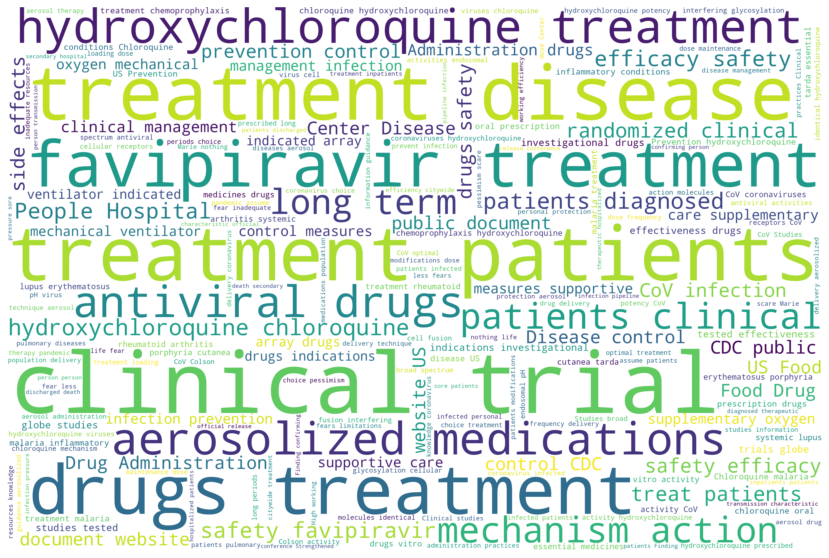

**Query : What is the effectiveness of drugs being developed and tried (like chloroquine, arbidol, remdesivir, and favipiravir) to treat COVID-19 patients.**

***Systematic review of the efficacy and safety of antiretroviral drugs against SARS, MERS or COVID‐19: initial assessment (2020.04.15):***

> Several randomized trials are planned to assess the safety and efficacy of antiretroviral drugs, including LPV/r, for the treatment of COVID‐19, MERS‐CoV and SARS‐CoV. While the conduct of such trials is challenging [41], high quality evidence is needed to improve clinical and programmatic decisions to use antiretroviral drugs for current and future coronavirus outbreaks.**

,publish_date,title,para_summary,para_similarity
575,2020-04-15,"Systematic review of the efficacy and safety of antiretroviral drugs against SARS, MERS or COVID‐19: initial assessment","Several randomized trials are planned to assess the safety and efficacy of antiretroviral drugs, including LPV/r, for the treatment of COVID‐19, MERS‐CoV and SARS‐CoV. While the conduct of such trials is challenging [41], high quality evidence is needed to improve clinical and programmatic decisions to use antiretroviral drugs for current and future coronavirus outbreaks.",78.299500
56,2020-04-12,Challenges and cares to promote rational use of chloroquine and hydroxychloroquine in the management of coronavirus disease 2019 (COVID-19) pandemic: a timely review,"Thus, clear information regarding the risk/benefit ratio of CQ and HCQ prescription needs to be shared among health professionals and extended to patients and the population. While researchers around the world are looking to develop target-specific drugs against the SARS-CoV-2 virus, current approaches need to be grounded in practices of patient care minimizing risk by rigorous screening and measuring of doses. There is no evidence that the use of CQ and HCQ has a preventive effect on the effects of COVID-19.",74.532112
2990,2020-04-07,Individual risk management strategy and potential therapeutic options for the COVID-19 pandemic,"Without the specific treatment for COVID-19, we here explore some potential therapeutic options of some prescribed medications and herbs. This protocol is accompanied by oxygen therapy and non-invasive ventilation for the most severely affected patients [111] .",74.144768
3820,2020-04-19,"COVID-19 and diabetes mellitus: what we know, how our patients should be treated now, and what should happen next","With global attention focused on the COVID-19 pandemic and urgent requests for emergency access to potential therapies, there is an understandable temptation to use drugs without fully proven safety and efficacy against the disease. Randomized clinical trials should be designed to examine the safety and efficacy of these drugs on chemoprophylaxis and treatment, including patients with diabetes, and the possibility of a quick interim analysis from these studies should be considered [59] [60] [61] .",73.262695
606,2020-04-14,Molecular mechanism of action of repurposed drugs and traditional Chinese medicine used for the treatment of patients infected with COVID-19: A systematic review,"Other clinical trials of favipiravir monotherapy or combination drug therapy are currently ongoing in China and Thailand to further evaluate the efficacy and safety of favipiravir for the treatment of COVID-19 disease. A different randomized clinical trial was conducted at three hospitals in China (Zhongnam Hospital of Wuhan University, Leishenshan Hospital, The Third People's Hospital of Hubei Province) to compare the efficacy and safety of favipiravir and arbidol to treat COVID-19 patients [88] . There is still insufficient data to determine the mechanism of action of favipiravir for the treatment of patients diagnosed with COVID-19.",72.595070
5358,2020-04-11,Clinical and microbiological effect of a combination of hydroxychloroquine and azithromycin in 80 COVID-19 patients with at least a six-day follow up: A pilot observational study,"Given the urgent therapeutic need to manage this disease with effective and safe drugs, and the negligible cost of both hydroxychloroquine and azithromycin, we believe that there is an urgent need to evaluate this strategy further, both to treat and cure patients at an early stage before irreversible severe respiratory complications take hold, and to decrease duration of carriage and avoid the spread of the disease. In conclusion, we have provided evidence of a beneficial effect of co-administration of hydroxychloroquine with azithromycin in the treatment of COVID-19 and its potential effectiveness in the early reduction of contagiousness.",72.571518

# Query : Clinical and bench trials to investigate less common viral inhibitors against COVID-19 such as naproxen, clarithromycin, and minocyclinethat that may exert effects on viral replication.

Selected top 132 publications

15 paragraphs shortlisted.

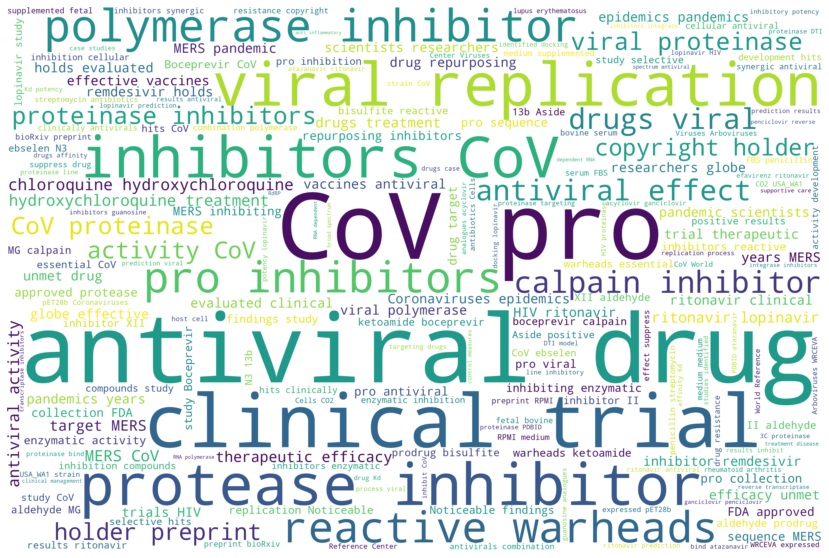

**Query : Clinical and bench trials to investigate less common viral inhibitors against COVID-19 such as naproxen, clarithromycin, and minocyclinethat that may exert effects on viral replication.**

***Hispidin and Lepidine E: two Natural Compounds and Folic acid as Potential Inhibitors of 2019-novel coronavirus Main Protease (2019-nCoVMpro), molecular docking and SAR study (2020.04.19):***

> Based on this study's results and other previous studies, we propose a therapeutic strategy to prevent and treat the virus infection. The potent metabolites hispidin and folic acid that inhibits the main protease of 2019-nCoV might be an effective strategy to treat 2019 novel coronavirus infected individuals. We have found that hispidin, lepidine E, and folic acid display a strong inhibitory activity on 3CL enzyme, which prevents spreading the infection by stopping the virus's cycle life. Those natural molecules also might become drug candidates as anti-CoViD-19 drug.**

,publish_date,title,para_summary,para_similarity
1121,2020-04-19,"Hispidin and Lepidine E: two Natural Compounds and Folic acid as Potential Inhibitors of 2019-novel coronavirus Main Protease (2019-nCoVMpro), molecular docking and SAR study","Based on this study's results and other previous studies, we propose a therapeutic strategy to prevent and treat the virus infection. The potent metabolites hispidin and folic acid that inhibits the main protease of 2019-nCoV might be an effective strategy to treat 2019 novel coronavirus infected individuals. We have found that hispidin, lepidine E, and folic acid display a strong inhibitory activity on 3CL enzyme, which prevents spreading the infection by stopping the virus's cycle life. Those natural molecules also might become drug candidates as anti-CoViD-19 drug.",73.974419
1554,2020-04-07,Protocol against coronavirus diseases in patients on renal replacement therapy: Dialysis and kidney transplant,"The results include antiviral drugs other than proteinase inhibitors, such as guanosine analogues (e.g., acyclovir, ganciclovir, and penciclovir), reverse transcriptase inhibitors, and integrase inhibitors. According to the prediction, viral proteinase-targeting drugs were predicted to act more favorably on the viral replication process than viral proteinase through the DTI model (Tables 2-6 ).",71.871620
3259,2020-03-18,"COVID-19, an emerging coronavirus infection: advances and prospects in designing and developing vaccines, immunotherapeutics, and therapeutics","Among the evaluated drugs, both remdesivir and chloroquine were found to be highly effective in controlling COVID-19 in vitro.63 The study also pointed out that the three nucleoside analogs such as ribavirin, penciclovir, and favipiravir may not have significant in vivo antiviral effects against COVID-19 since higher concentrations were required to reduce the viral infection in vitro. Oral administration of neuraminidase inhibitors such as oseltamivir has been used as an empirical drug for COVID-19 suspected cases in China hospitals even though there is no evidence of its efficacy.2 Recently, the in vitro antiviral efficacy of approved drugs such as ribavirin, penciclovir, nitazoxanide, nafamostat, and chloroquine was compared with that of the two broad-spectrum antiviral drugs remdesivir and favipiravir for COVID-19. Both remdesivir and chloroquine are being used for the treatment of other diseases and have a well-defined safety profile. Hence, such drugs can be used for evaluating their efficacy in patients of novel CoV infections.",71.619720
3257,2020-03-18,"COVID-19, an emerging coronavirus infection: advances and prospects in designing and developing vaccines, immunotherapeutics, and therapeutics","Furthermore, RNA synthesis inhibitors (like 3TC, TDF), remdesivir, neuraminidase inhibitors, peptide (EK1), anti-inflammatory drugs, abidol, Chinese traditional medicine, such as Lianhuaqingwen and ShuFengJieDu Capsules, could be the promising COVID-19 treatments.2 However, further clinical trials are required for confirming safety and efficacy for COVID-19. Hence, current efforts should be directed toward identifying and evaluating drugs and immunotherapeutics that have proven efficacy against viruses similar to COVID-19. The guidance to COVID-19 control might be based on existing measures for MERS and SARS, with some further precautions due to the unknown nature of this new CoV.14,73 The main treatments such as mechanical ventilation, ICU admission, and symptomatic and supportive care are recommended for severe cases. It may take months to even several years for researchers to develop, produce, standardize, evaluate, approve, and commercialize therapeutic agents for COVID-19. A major limiting factor in the quest for identifying an ideal vaccine or therapeutic agent is time.",71.087708
111,2020-04-20,"Boceprevir, GC-376, and calpain inhibitors II, XII inhibit SARS-CoV-2 viral replication by targeting the viral main protease","As

# Query : Methods evaluating potential complication of Antibody-Dependent Enhancement (ADE) in vaccine recipients for COVID 19 or the novel coronavirus.

Selected top 273 publications

15 paragraphs shortlisted.

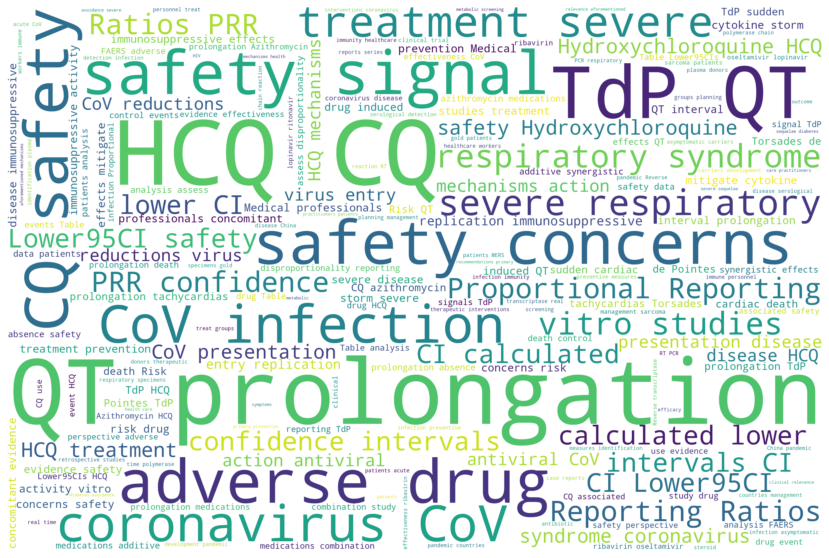

**Query : Methods evaluating potential complication of Antibody-Dependent Enhancement (ADE) in vaccine recipients for COVID 19 or the novel coronavirus.**

***Effectiveness and safety of antiviral or antibody treatments for coronavirus (2020.03.23):***

> o Monoclonal antibodies approved for use in COVID-19 or currently in pre-clinical trials (animal studies, excluding in vitro studies) for treating COVID-19.**

,publish_date,title,para_summary,para_similarity
24,2020-03-23,Effectiveness and safety of antiviral or antibody treatments for coronavirus,"o Monoclonal antibodies approved for use in COVID-19 or currently in pre-clinical trials (animal studies, excluding in vitro studies) for treating COVID-19.",73.097672
23,2020-03-23,Effectiveness and safety of antiviral or antibody treatments for coronavirus,"o Antiviral medications approved for use in COVID-19 or currently in pre-clinical trials (animal studies, excluding in vitro studies) for treating COVID-19 (see Table 1 ).",70.316437
5373,2020-03-23,"An exploratory randomized, controlled study on the efficacy and safety of lopinavir/ritonavir or arbidol treating adult patients hospitalized with mild/moderate COVID-19 (ELACOI)","Additionally, despite lacking a valid estimate of efficacy, the combination of LPV/r has been associated with significantly fewer adverse clinical outcomes (acute respiratory distress syndrome or death) in 41 patients with SARS compared with ribavirin alone in 111 historical controls (2.4% versus 28.8%, P= 0.001) in the 21 days after the onset of symptoms [ 9 ] . Thus, based on in vitro testing and previous clinical trials demonstrating its efficacy against other coronaviruses, LPV/r was regarded as an option for treating COVID-19.",69.668808
3339,2020-04-18,Lack of coordination and medical disinformation in Canadian self-assessment tools for COVID-19,"Generally the self-assessment tools can be described as having three parts: (i) screening for health events that require immediate or urgent medical attention, (ii) screening for COVID-19 associated symptoms, and (iii) screening for possible exposure, either through travel outside Canada or contact with a confirmed case. For clarity of presentation we present results for each of these parts in turn.",68.963959
3362,2020-04-23,Practical recommendations for the management of diabetes in patients with COVID-19,"This includes recommendations regarding both the need for primary prevention of diabetes as well as the avoidance of severe sequelae of diabetes triggered by unidentified or poorly managed diabetes (figure). We have compiled a simple flowchart for the metabolic screening and management of patients with COVID-19 and diabetes or at risk for metabolic disease. The clinical relevance of the aforementioned mechanisms is currently uncertain, but health-care practitioners should be aware of their implications for patients with diabetes. Furthermore, special considerations on anti-diabetes drugs commonly used in patients with type 2 diabetes in view of COVID-19 are presented in the panel.",68.628372
6992,2020-04-29,Comparison of four new commercial serologic assays for determination of SARS-CoV-2 IgG,"Especially in healthcare workers, this is of outmost importance to identify immune personnel that will treat vulnerable patient groups and for the planning and management of infection preventive measures. It also allows the identification of plasma donors for therapeutic interventions.",68.583038
49,2020-03-23,Effectiveness and safety of antiviral or antibody treatments for coronavirus,"None of the trials, cohorts, or retrospective studies demonstrated statistically significant results between any of the comparisons (i.e., in favour of or against the effectiveness of ribavirin, oseltamivir or lopinavir/ritonavir) in reducing the risk of ICU admission for patients with SARS or MERS. The case reports and series were similarly inconclusive, none of the study authors reported a particular advantage for patients with COVID-19, SARS, or MERS treated with ribavirin, oseltamivir, or lopinavir/ritonavir. Of the 21 studies reporting this outcome, one was a randomized trial 6 comparing ribavirin supplemented with hydrocortisone to ribavirin alone; three were cohort studies 14, 15, 17 comparing oseltamivir to steroid treatment alone, ribavirin with continuous steroid treatment to ribavirin with high-dose 'pulse' steroids, and riba

# Query : Exploration of use of best animal models and their predictive value for a human vaccine.

Selected top 1387 publications

15 paragraphs shortlisted.

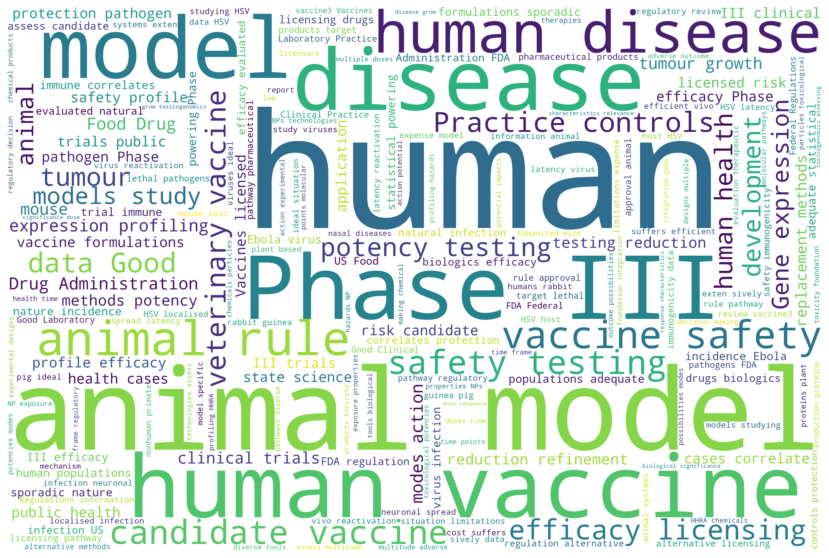

**Query : Exploration of use of best animal models and their predictive value for a human vaccine.**

***The interface of animal and human vaccines (2012.06.30):***

> A final and important interface between animal and human vaccines is the use of animal models for licensure of human vaccines for which it is impossible or unethical to use humans for efficacy testing. Burns describes regulatory aspects of the U.S. Food and Drug Administration (FDA) rule, 212 CFR 601.90, commonly known as the 'Animal Rule' which allows for the use of animal data to support efficacy claims of a human vaccine. Because animal models that reflect human disease are a requisite for licensure under this rule, great efforts are being made to develop suitable animal models, especially nonhuman primate models for a variety of diseases.**

,publish_date,title,para_summary,para_similarity
29699,2012-06-30,The interface of animal and human vaccines,"A final and important interface between animal and human vaccines is the use of animal models for licensure of human vaccines for which it is impossible or unethical to use humans for efficacy testing. Burns describes regulatory aspects of the U.S. Food and Drug Administration (FDA) rule, 212 CFR 601.90, commonly known as the 'Animal Rule' which allows for the use of animal data to support efficacy claims of a human vaccine. Because animal models that reflect human disease are a requisite for licensure under this rule, great efforts are being made to develop suitable animal models, especially nonhuman primate models for a variety of diseases.",79.392647
6282,2019-03-31,Comparative models for human nasal infections and immunity,"Primates as models for the study of human nasal diseases and immunity Due to anatomical and immunological similarities, the use of nonhuman primate models confers great advantages in the evaluation of therapeutic drugs, treatments and vaccines. Of particular interest for the study of nasal immune responses and human nasal diseases, primates have tonsils arranged in a Waldeyer's ring similar to humans (Ludlow et al., 2013) . 13.",73.633873
7845,2015-12-31,Development of a DNA-based microarray for the detection of zoonotic pathogens in rodent species,"The aim of this report is to explicate the design, development and evaluation of a microarray platform for use as a screening tool, which combines ease of use and rapid identification of a number of rodent-borne pathogens of zoonotic importance. There are currently no microarrays for the detection of multiple rodent-borne pathogens.",72.538361
37667,2013-01-07,Gene expression profiling to identify potentially relevant disease outcomes and support human health risk assessment for carbon black nanoparticle exposure,"As our knowledge of molecular pathways, and of the diverse tools used to decipher their biological significance, dose-response characteristics and relevance to human disease continues to grow, we anticipate that toxicogenomics will become increasingly useful in assessing the toxicological hazards of a wide range of test articles, and by extension, for HHRA. Due to the unique properties of NPs, powerful technologies that can assess a multitude of adverse outcome possibilities will be required to elucidate their modes of action and potential impacts on human health within a time-frame that is suitable for prompt regulatory decision making. In order to establish a strong foundation for the integration of gene expression profiling into HHRA, it will be necessary for the approach employed here to be applied to a variety of additional chemicals/particles that span a wide range of toxicological potencies and modes of action, and using a variety of experimental designs (e.g., multiple doses and time-points). Gene expression profiling offers a promising approach to decipher the largely unknown hazards of NP exposure. This same premise should hold true for any new chemical products, for which toxicity is largely or completely unknown.",71.392807
29120,2015-04-15,Optimization of antigen dose for a receptor-binding domain-based subunit vaccine against MERS coronavirus,"This study provides important information for rational design of optimal dosages of vaccines against MERS and other emerging infectious diseases for their future clinical trials. Application of the lowest possible amount of the antigen and fewer injections is an important dose sparing strategy for a vaccine with low productivity (e.g., a subunit vaccine), especially during a pandemic or epidemic of an emerging infectious disease, like MERS.",71.388016
16464,2011-12-31,Non-animal replacement methods for veterinary vaccine potency testing: state of the science and future directions,"The final plenary session addressed methods and approaches for reducing, refining, and replacing animal use 

# Query : Capabilities to discover a therapeutic for COVID 19 or the novel coronavirus, and clinical effectiveness studies to discover therapeutics, to include antiviral agents.

Selected top 172 publications

15 paragraphs shortlisted.

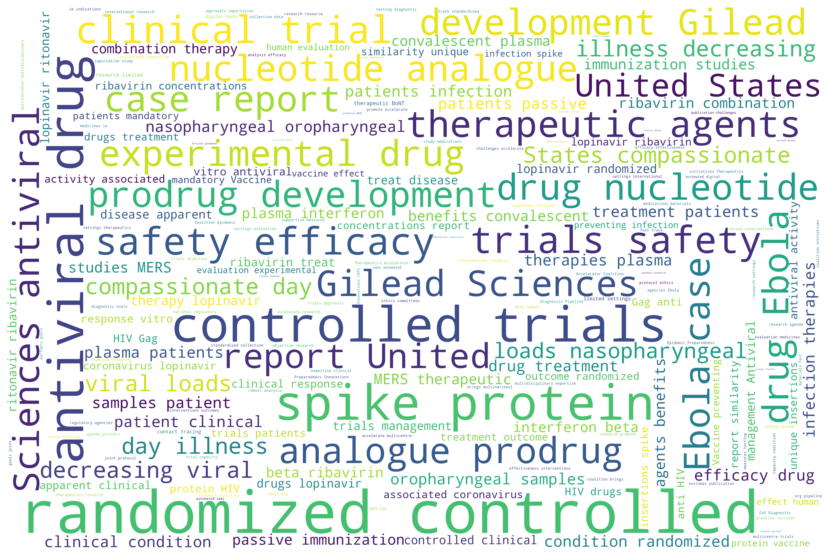

**Query : Capabilities to discover a therapeutic for COVID 19 or the novel coronavirus, and clinical effectiveness studies to discover therapeutics, to include antiviral agents.**

***Applying the unified models of ecology to forecast epidemics, with application to Covid-19 (2020.04.11):***

> They can start with measures to reduce the spread of the disease, such as social distancing and facemasks in the case of Covid-19, and expand to increasing numbers of hospital beds as needs continue, and to methods to help people recover, but must continue to vaccines to further reduce the spread, possibly to drugs to reduce susceptibility or infectivity, and to continual quests for antimicrobials to cure those infected. The message here is that for a disease to be conquered, efforts to control it must be continually increasing. Relaxing on the pursuit of new efforts of control may not result in the green line in Figure 6 .**

,publish_date,title,para_summary,para_similarity
2632,2020-04-11,"Applying the unified models of ecology to forecast epidemics, with application to Covid-19","They can start with measures to reduce the spread of the disease, such as social distancing and facemasks in the case of Covid-19, and expand to increasing numbers of hospital beds as needs continue, and to methods to help people recover, but must continue to vaccines to further reduce the spread, possibly to drugs to reduce susceptibility or infectivity, and to continual quests for antimicrobials to cure those infected. The message here is that for a disease to be conquered, efforts to control it must be continually increasing. Relaxing on the pursuit of new efforts of control may not result in the green line in Figure 6 .",71.848282
3004,2020-04-15,"Systematic review of the efficacy and safety of antiretroviral drugs against SARS, MERS or COVID‐19: initial assessment","Several randomized trials are planned to assess the safety and efficacy of antiretroviral drugs, including LPV/r, for the treatment of COVID‐19, MERS‐CoV and SARS‐CoV. While the conduct of such trials is challenging [41], high quality evidence is needed to improve clinical and programmatic decisions to use antiretroviral drugs for current and future coronavirus outbreaks.",71.803177
738,2020-06-30,3CLpro inhibitors as a potential therapeutic option for COVID-19: Available evidence and ongoing clinical trials,Letter to the Editor 3CL pro inhibitors as a potential therapeutic option for COVID-19: Available evidence and ongoing clinical trials,71.540581
1391,2020-03-25,Corrigendum to “Traditional Chinese medicine for COVID-19 treatment” [Pharmacol. Res. 155 (2020) 104743],Letter to the Editor 3CL pro inhibitors as a potential therapeutic option for COVID-19: Available evidence and ongoing clinical trials,71.540581
227,2020-04-17,Automated and semi-automated contact tracing: Protocol for a rapid review of available evidence and current challenges to inform the control of COVID-19,"Articles must refer to automated or semi-automated digital tools for contact tracing in human populations of COVID-19, another respiratory disease with pandemic potential (limited to SARS, MERS, or influenza), or Ebola. We will restrict interventions to these disease groups to ensure that the results are applicable to COVID-19. The following digital tools will be eligible for inclusion: web-based (e.g. where a case inputs their contacts), stand-alone applications used on either a smartphone and/or computer, tools developed as an add-on to an existing application (e.g. adding a COVID-19 tracker to an existing health, mapping or messaging application), mobile signal traffic from telecommunications operators. Although Ebola is not a respiratory illness, novel methods for contact tracing in challenging circumstances were developed to contain this disease in conjunction with similar measures -for example, quarantines -to those applied in the current COVID-19 pandemic, such that findings may be applicable. We will include articles that provide a comparison either with no contact tracing, contact tracing without automated or semi-automated digital tools, other non-pharmaceutical disease control interventions, as well as articles without a comparator.",69.972847
126,2020-04-29,Perspectives for the use of therapeutic Botulinum toxin as a multifaceted candidate drug to attenuate COVID-19,"Adding to that, therapeutic BoNT, regarded as a magic bullet appears to have a proven curative effect against many explicated symptoms of COVID-19 including the respiratory failure, cardiac defects and neurological deficits. While plans like nation-wide lockdown, social distancing and self-quarantine have been imposed by many countries to avoid the spread of SARS-CoV-2, the establishment of vaccination, identifying the pharmacological strategies and disease modifying therapies J o u r n a l P r e -p r o o f treatment like Ivermectin [78] have gained the fro

# Query : Alternative models to aid decision makers in determining how to prioritize and distribute scarce, newly proven therapeutics as production ramps up for COVID 19 or the novel coronavirus. This could include identifying approaches for expanding production capacity to ensure equitable and timely distribution to populations in need.

Selected top 173 publications

15 paragraphs shortlisted.

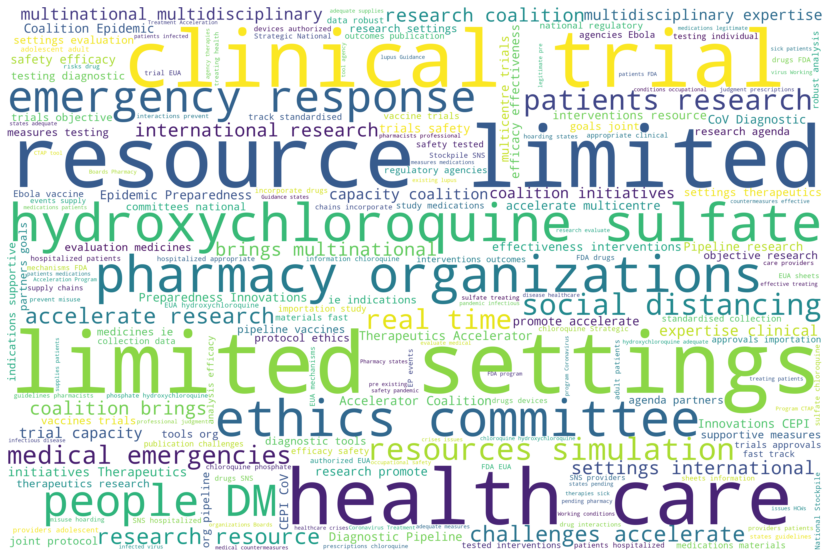

**Query : Alternative models to aid decision makers in determining how to prioritize and distribute scarce, newly proven therapeutics as production ramps up for COVID 19 or the novel coronavirus. This could include identifying approaches for expanding production capacity to ensure equitable and timely distribution to populations in need.**

***Pharmacy Emergency Preparedness and Response (PEPR) framework for expanding pharmacy professionals’ roles and contributions to emergency preparedness and response during the COVID-19 pandemic and beyond (2020.04.10):***

> The PEPR Framework can be utilized to develop, implement, evaluate, and disseminate results in order to strengthen existing efforts and to establish new initiatives in EP&R. The PEPR Framework provides recommendations for six specific areas of individual or collective actions for pharmacy researchers, educators, professionals, organizations and allies to further prepare and respond to the current COVID-19 pandemic and future public health emergencies. Yet, there are additional opportunities for enhancing the pharmacist's roles and recognition in public health, specifically with regards to EP&R as further outlined in the PEPR Framework (Table 1) .**

,publish_date,title,para_summary,para_similarity
1773,2020-04-10,Pharmacy Emergency Preparedness and Response (PEPR) framework for expanding pharmacy professionals’ roles and contributions to emergency preparedness and response during the COVID-19 pandemic and beyond,"The PEPR Framework can be utilized to develop, implement, evaluate, and disseminate results in order to strengthen existing efforts and to establish new initiatives in EP&R. The PEPR Framework provides recommendations for six specific areas of individual or collective actions for pharmacy researchers, educators, professionals, organizations and allies to further prepare and respond to the current COVID-19 pandemic and future public health emergencies. Yet, there are additional opportunities for enhancing the pharmacist's roles and recognition in public health, specifically with regards to EP&R as further outlined in the PEPR Framework (Table 1) .",87.413383
858,2020-04-06,COVID19-Tracker: A shiny app to produce comprehensive data visualization for SARS-CoV-2 epidemic in Spain,"In summary, this application, easy to use, come to fill a gap in this particular scenario for the visualization of epidemiological data for the COVID-19 epidemic in Spain. We continue to plan improvements to the app to include new analytics and visualizations. Aos, the application could be extensible for use in other countries or geographic areas.",84.915375
1757,2020-04-10,Pharmacy Emergency Preparedness and Response (PEPR) framework for expanding pharmacy professionals’ roles and contributions to emergency preparedness and response during the COVID-19 pandemic and beyond,"Responding to the COVID-19 pandemic, professional pharmacy organizations collaborated to provide a joint policy statement with several recommendations based on existing structures (e.g. hospitals and health-systems, long-term care facilities, outpatient clinics, and community pharmacies, drug information centers, tele pharmacy/call centers) in partnerships with health departments and emergency response teams) to enhance processes for pharmacists' role in emergency response. Pharmacists should continue to monitor and report adverse events for newly approved drugs and vaccines in emergencies.",83.389900
4290,2020-04-11,"Applying the unified models of ecology to forecast epidemics, with application to Covid-19","They can start with measures to reduce the spread of the disease, such as social distancing and facemasks in the case of Covid-19, and expand to increasing numbers of hospital beds as needs continue, and to methods to help people recover, but must continue to vaccines to further reduce the spread, possibly to drugs to reduce susceptibility or infectivity, and to continual quests for antimicrobials to cure those infected. The message here is that for a disease to be conquered, efforts to control it must be continually increasing. Relaxing on the pursuit of new efforts of control may not result in the green line in Figure 6 .",83.058136
1750,2020-04-10,Pharmacy Emergency Preparedness and Response (PEPR) framework for expanding pharmacy professionals’ roles and contributions to emergency preparedness and response during the COVID-19 pandemic and beyond,"24 To prevent misuse and hoarding, twenty two (22) states issued guidelines for pharmacists who are being allowed to ""use their professional judgment when filling prescriptions for chloroquine and hydroxychloroquine"" to ensure adequate supplies for patients with ongoing need for these medications for legitimate and/or pre-existing conditions such as lupus. These drugs will be distributed from the SNS to states for providers to prescribe to adolescent and adult patients hospitalized with COVID-19, as appropriate, when a clinical trial is not available or feasible. 25 Guidance for remaining states are pending and pharmacy organizations and Boards of Pharmacy in these states should work to ensure that there are adequate measures taken to ensure medications for patients w

# Query : Efforts targeted at a universal coronavirus vaccine.

Selected top 28 publications

15 paragraphs shortlisted.

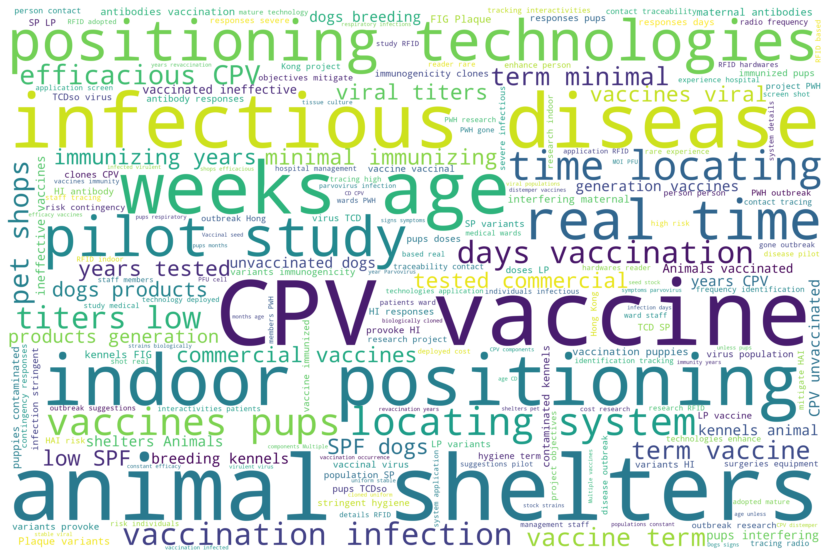

**Query : Efforts targeted at a universal coronavirus vaccine.**

***Custom-made vaccines at speed (2003.06.15):***

> To virologists,' explains Richard Webby, a postdoctoral fellow in the Department of Infectious Diseases at St Jude, 'reverse genetics means the production of a virus from cloned DNA'. A team led by Yoshihiro Kawaoka, Professor of Virology at the University of Wisconsin-Madison (http://www.vetmed.wisc.edu) was the first to achieve this feat for influenza, a segmented negative-sense RNA virus, in 1999 [1] . '**

,publish_date,title,para_summary,para_similarity
187,2003-06-15,Custom-made vaccines at speed,"To virologists,' explains Richard Webby, a postdoctoral fellow in the Department of Infectious Diseases at St Jude, 'reverse genetics means the production of a virus from cloned DNA'. A team led by Yoshihiro Kawaoka, Professor of Virology at the University of Wisconsin-Madison (http://www.vetmed.wisc.edu) was the first to achieve this feat for influenza, a segmented negative-sense RNA virus, in 1999 [1] . '",65.351540
185,2003-06-15,Custom-made vaccines at speed,"A concept called reverse genetics has recently enabled researchers at the St Jude Children's Research Hospital (http://www.stjude.org) to construct an experimental vaccine against H5N1, a potential pandemic influenza strain, in less than a month. A similar approach could be used to develop vaccines for severe acute respiratory syndrome (SARS).",61.931431
26,1999-12-31,Canine Viral Vaccines at a Turning Point—A Personal Perspective,"9 Because efficacious CPV-2 and distemper vaccines have been shown to provide immunity for at least 5 years, revaccination at 3-5 years, after the first year, seems a conservative strategy. Multiple vaccines are suggested at 12 weeks of age, unless pups are at high risk for respiratory infections (e.g., animal shelters, pet shops, etc.).",53.293419
557,2006-01-01,Laboratory-acquired infections: Are microbiologists at risk?,"Laboratory safety should focus on training employees to practice standard precautions at all times, process specimens in a BSC, use appropriate containment equipment and safety barriers when necessary, decontaminate work surfaces at least daily and following a spill, and properly dispose of hazardous waste (Table 3) .",52.243221
431,2020-01-01,How an Australian researcher ended up in the spotlight at a White House coronavirus briefing | Science | AAAS,"After incubation the cells were harvested, frozen and thawed once, clarified at 2000 x g for 30 rain at 4°C, and the supernatant containing infectious virus particles was stored at -70°C until required. The cell monolayers in flat bottles were infected at an input multiplicity of 0.1 infectious particles per cell and, following an adsorption period of 1 h at 33°C, were incubated at 33°C for 24 h in Eagle's BME medium with 2% newborn calf serum. KI, LP, PR and TO were isolated in tissue culture at the Common Cold Unit, Salisbury, U.K., from nasal washings of subjects with natural colds [6, 7] . The viruses were grown in stationary monolayer cultures of human embryo lung cells of the MRC continuous (MRCc) line, originally obtained from Dr. A.F. Bradburne [8] .",51.738960
188,2003-06-15,Custom-made vaccines at speed,"The classic method of making a vaccine to a new flu variant, explains Webby, is to co-infect hens eggs with the field isolate and a vaccine strain and then to genetically select for reassorted viruses containing the desired mix of genome fragments, a process that can take many weeks.",51.666565
663,2005-11-23,Luxury at a Cost? Recombinant Mouse Hepatitis Viruses Expressing the Accessory Hemagglutinin Esterase Protein Display Reduced Fitness In Vitro,"This caused a frameshift at Pro 404 , immediately upstream of the predicted transmembrane domain. Sequence analysis revealed that three of them (type 1) contained a one-nucleotide insertion in the HE gene; an extra cytidylate residue had been added to a stretch of five nucleotides, located at positions 1209 to 1213. The mutant viruses expressed HE at intracellular levels equal to (type 2) or only slightly less than (type 1) that seen for rMHV-HE ϩ (Fig. 6, top panel) , yet they failed to incorporate HE into their virions (Fig. 6, bottom panel) . The other mutants (type 2) had a single nucleotide substitution in the HE gene, G 70 3T, as a result of which Gly 24 was replaced by Trp. To determine the defects in these spontaneous O-acetylesterase-deficient mutants, nine of them were randomly selected by plaque purification from

# Query : Efforts to develop animal models and standardize challenge studies for COVID 19 or the novel coronavirus

Selected top 197 publications

15 paragraphs shortlisted.

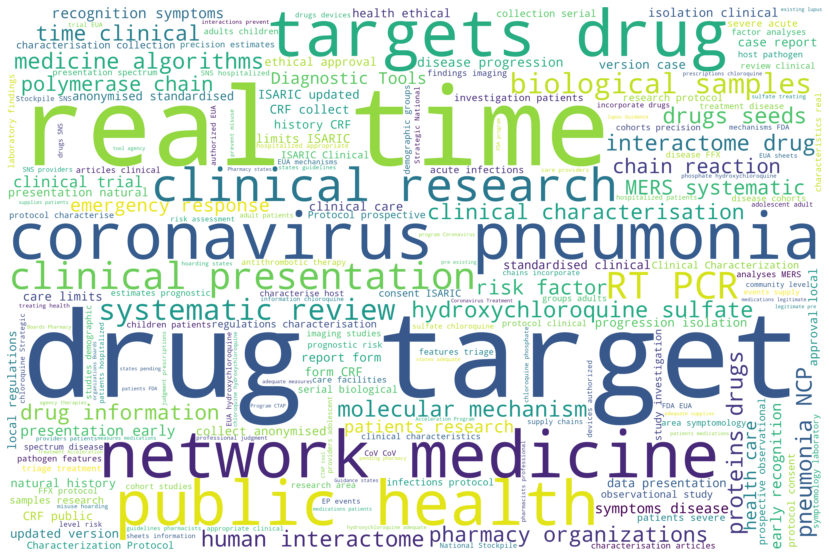

**Query : Efforts to develop animal models and standardize challenge studies for COVID 19 or the novel coronavirus**

***An evidence-based framework for priority clinical research questions for COVID-19 (2020.03.31):***

> In designing protocols for mortality or severe illness risk factors for COVID-19, case-control studies or prospective cohort studies should be used with an end-point at 90 days, so as not to miss late deaths. Whatever the optimal end-point for assessing outcome, standardising this outcome measure across studies will allow researchers to contribute to core data sets. Many studies identified from the MERS and SARS systematic review were retrospective cohort studies and poor outcomes were assessed 21-30 days from symptom onset.**

,publish_date,title,para_summary,para_similarity
1221,2020-03-31,An evidence-based framework for priority clinical research questions for COVID-19,"In designing protocols for mortality or severe illness risk factors for COVID-19, case-control studies or prospective cohort studies should be used with an end-point at 90 days, so as not to miss late deaths. Whatever the optimal end-point for assessing outcome, standardising this outcome measure across studies will allow researchers to contribute to core data sets. Many studies identified from the MERS and SARS systematic review were retrospective cohort studies and poor outcomes were assessed 21-30 days from symptom onset.",73.130997
4780,2020-04-14,Review on the global epidemiological situation and the efficacy of chloroquine and hydroxychloroquine for the treatment of COVID-19,"It is interesting to do more research to find a specific vaccine or drug for this epidemic in order to manage this health crisis effectively, to limit the rapid spread and to save humanity. However, given the current serious global epidemiological situation and given the urgent therapeutic need. Despite efforts in clinical trials to assess the efficacy of drugs, previously used in other diseases, for the treatment of COVID-19.",72.473511
3130,2020-03-27,$\alpha$-Satellite: An AI-driven System and Benchmark Datasets for Hierarchical Community-level Risk Assessment to Help Combat COVID-19,"There have been several works on using AI and machine learning techniques to help combat COVID-19: in the biomedical domain, [6, 24, 28, 32, 35] use deep learning methods for COVID-19 pneumonia diagnosis and genome study; while [26, 36] develop learning-based models to predict severity and survival for patients. Another research direction is to utilize public accessible data to help the estimation of infection cases or forecast the COVID-19 outbreak [14, 17, 18, 22, 25, 27, 46] . To meet this urgent need and to bridge the research gap, in this work, by advancing capabilities of AI and leveraging the large-scale and real-time data generated from heterogeneous sources, we propose and develop an AI-driven system, named α-Satellite, to provide hierarchical community-level risk assessment at the first attempt to help combat the deadly and fast evolving COVID-19 pandemic. However, most of these existing works mainly focus on Wuhan China; the studies of using computational models to combat COVID-19 in the U.S. are scarce and there has no work on community-level risk assessment to assist with community mitigation by far.",70.513168
3044,2020-04-10,Pharmacy Emergency Preparedness and Response (PEPR) framework for expanding pharmacy professionals’ roles and contributions to emergency preparedness and response during the COVID-19 pandemic and beyond,"These drugs will be distributed from the SNS to states for providers to prescribe to adolescent and adult patients hospitalized with COVID-19, as appropriate, when a clinical trial is not available or feasible. On March 31, 2020, the FDA announced a new program known as the Coronavirus Treatment Acceleration Program (CTAP) to use every tool at the agency's disposal to bring new therapies to sick patients as quickly as possible, while at the same time supporting research to further evaluate whether these medical countermeasures are safe and effective for treating patients infected with this novel virus. 24 To prevent misuse and hoarding, twenty two (22) states issued guidelines for pharmacists who are being allowed to ""use their professional judgment when filling prescriptions for chloroquine and hydroxychloroquine"" to ensure adequate supplies for patients with ongoing need for these medications for legitimate and/or pre-existing conditions such as lupus.",69.982109
1219,2020-03-31,An evidence-based framework for priority clinical research questions for COVID-19,"This CRF is being rolled out as a tool for public health and may or may not require ethical approval according to local reg

# Query : Efforts to develop prophylaxis clinical studies and prioritize in healthcare workers for COVID 19 or the novel coronavirus

Selected top 299 publications

15 paragraphs shortlisted.

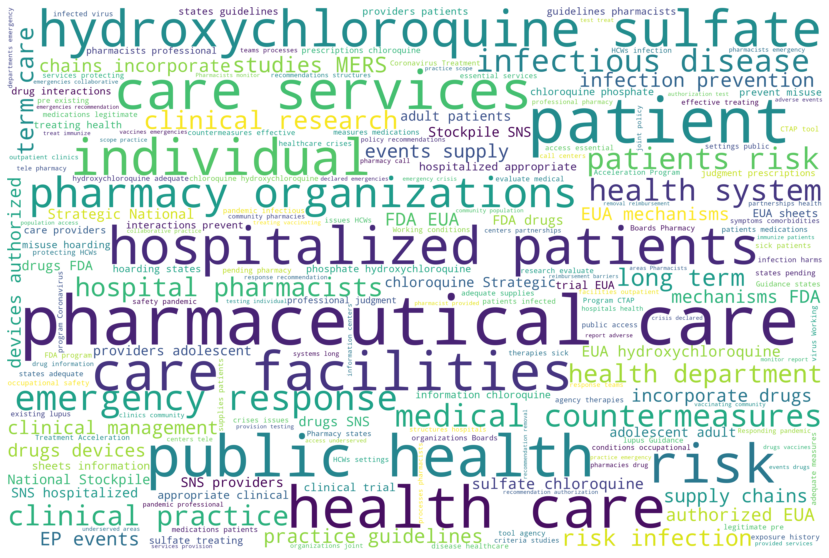

**Query : Efforts to develop prophylaxis clinical studies and prioritize in healthcare workers for COVID 19 or the novel coronavirus**

***Pharmacy Emergency Preparedness and Response (PEPR) framework for expanding pharmacy professionals’ roles and contributions to emergency preparedness and response during the COVID-19 pandemic and beyond (2020.04.10):***

> Responding to the COVID-19 pandemic, professional pharmacy organizations collaborated to provide a joint policy statement with several recommendations based on existing structures (e.g. hospitals and health-systems, long-term care facilities, outpatient clinics, and community pharmacies, drug information centers, tele pharmacy/call centers) in partnerships with health departments and emergency response teams) to enhance processes for pharmacists' role in emergency response. Pharmacists should continue to monitor and report adverse events for newly approved drugs and vaccines in emergencies.**

,publish_date,title,para_summary,para_similarity
5314,2020-04-10,Pharmacy Emergency Preparedness and Response (PEPR) framework for expanding pharmacy professionals’ roles and contributions to emergency preparedness and response during the COVID-19 pandemic and beyond,"Responding to the COVID-19 pandemic, professional pharmacy organizations collaborated to provide a joint policy statement with several recommendations based on existing structures (e.g. hospitals and health-systems, long-term care facilities, outpatient clinics, and community pharmacies, drug information centers, tele pharmacy/call centers) in partnerships with health departments and emergency response teams) to enhance processes for pharmacists' role in emergency response. Pharmacists should continue to monitor and report adverse events for newly approved drugs and vaccines in emergencies.",78.880455
423,2020-03-26,Guidelines for preventing respiratory illness in older adults aged 60 years and above living in long-term care: A rapid review of clinical practice guidelines,"The WHO commissioned a rapid review to address the urgent question of the infection prevention and control practices/measures for respiratory viruses in long-term care facilities that could be applied to COVID-19. None of the clinical practice guidelines specifically focused on issues related to residents with respiratory illness and severe comorbidities or frailty. Furthermore, none focused on issues in LMIC or different cultural contexts. A comprehensive literature search of both electronic databases and grey literature sources resulted 17 included clinical practice guidelines.",78.811241
1327,2020-02-23,"ACP risk grade: a simple mortality index for patients with confirmed or suspected severe acute respiratory syndrome coronavirus 2 disease (COVID-19) during the early stage of outbreak in Wuhan, China","We aimed to characterize the clinical features of hospitalized patients with confirmed or suspected COVID-19, and develop a mortality risk index for COVID-19 patients. Background: Since the severe acute respiratory syndrome coronavirus 2 (SARS-CoV-2) disease (COVID-19) outbreaks in Wuhan, China, healthcare systems capacities in highly endemic areas have been overwhelmed. Approaches to efficient management are urgently needed and key to a quicker control of the outbreaks and casualties.",76.800369
5211,2020-04-03,Hospital pharmacists’ pharmaceutical care for hospitalized patients with COVID-19: Recommendations and guidance from clinical experience,"For COVID-19 patients receiving centralized hospitalized treatment, pharmaceutical care services are https://doi.org/10.1016/j.sapharm.2020.03.027 Received 31 March 2020; Accepted 31 March 2020 indispensable supplement for clinical treatment and management, which is of great significance for improving the level of drug therapy, improving patient's outcome and promoting the overall pandemic control. According to International Pharmaceutical Federation (FIP) guidance for pharmacists, 6 as a member of the healthcare professionals, it's one of the most essential responsibilities for hospital pharmacists to join the medical collaborative team and provide pharmaceutical care services to COVID-19 patients.",76.545692
5307,2020-04-10,Pharmacy Emergency Preparedness and Response (PEPR) framework for expanding pharmacy professionals’ roles and contributions to emergency preparedness and response during the COVID-19 pandemic and beyond,"24 Working conditions and occupational safety: During a pandemic or similar infectious disease healthcare crises, there are competing issues for HCWs and the settings in which they work: (1) providing public access to essential services and (2) protecting HCWs from infection and other harms. These drugs will be distributed from the SNS to states for providers to prescribe to adolescent and adult patients hospitalized with COVID-19, as appropriate, when a clinical trial is not available or feasible. 24 To prevent misuse and hoard

# Query : Approaches to evaluate risk for enhanced disease after vaccination for COVID 19 or the novel coronavirus

Selected top 331 publications

15 paragraphs shortlisted.

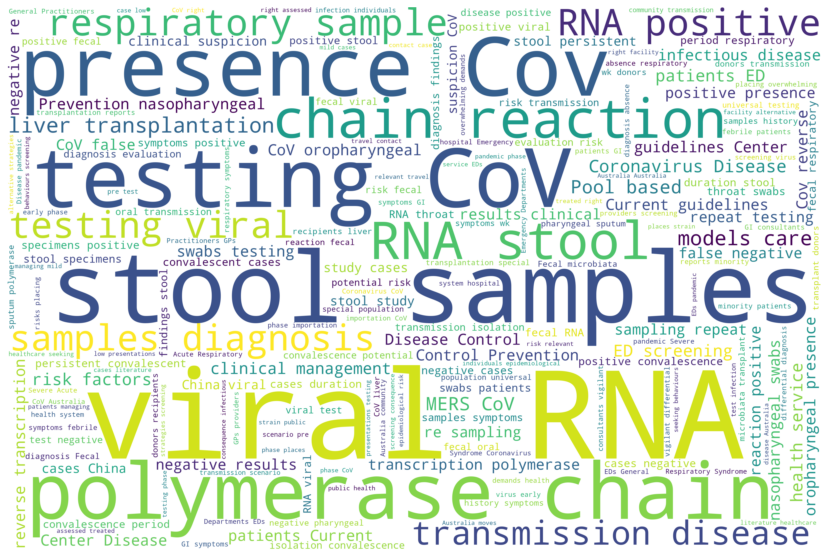

**Query : Approaches to evaluate risk for enhanced disease after vaccination for COVID 19 or the novel coronavirus**

***Estimation of risk factors for COVID-19 mortality - preliminary results (2020.02.25):***

> The search performed in Pubmed on the 21 th of January 2020 using the following keywords (("odds ratio" OR "risk ratio" OR "relative risk" OR risk)) AND (SARS-CoV OR SARS OR MERS-CoV OR MERS OR corona OR coronavirus) and updated on the 24 th of January 2020 produced no results for studies reporting risk factors for SARS-CoV. Therefore, it is of extreme importance to briskly define the odds ratio for mortality adjusted to comorbidities which are highly prevalent globally, according to age and gender, in order to prevent COVID-19 specific mortality. The risk factors for MERS-CoV were established after analysing data collected from the World Health organization between 2012 and 2018 14 , where males seemed to be more affected than females, and also age over 30 years-old or the presence or comorbidities. Besides these baseline characteristics, ethnicity also presented statistically significant odds ratios.**

,publish_date,title,para_summary,para_similarity
2602,2020-02-25,Estimation of risk factors for COVID-19 mortality - preliminary results,"The search performed in Pubmed on the 21 th of January 2020 using the following keywords ((""odds ratio"" OR ""risk ratio"" OR ""relative risk"" OR risk)) AND (SARS-CoV OR SARS OR MERS-CoV OR MERS OR corona OR coronavirus) and updated on the 24 th of January 2020 produced no results for studies reporting risk factors for SARS-CoV. Therefore, it is of extreme importance to briskly define the odds ratio for mortality adjusted to comorbidities which are highly prevalent globally, according to age and gender, in order to prevent COVID-19 specific mortality. The risk factors for MERS-CoV were established after analysing data collected from the World Health organization between 2012 and 2018 14 , where males seemed to be more affected than females, and also age over 30 years-old or the presence or comorbidities. Besides these baseline characteristics, ethnicity also presented statistically significant odds ratios.",68.522301
469,2020-03-16,"National Institute for the Infectious Diseases “L. Spallanzani”, IRCCS. Recommendations for COVID-19 clinical management","Considering the burden of clinical symptoms and the higher risk for complications, the goals of clinical management are, in addition to the ones stated for the asymptomatic patients: Individuals presenting COVID-19 clinical symptoms or signs.",67.643318
558,2020-03-31,An evidence-based framework for priority clinical research questions for COVID-19,The suspected major risk factors for COVID-19 are visiting the Wuhan market or being in contact with someone who had visited the market. The above-mentioned WHO FFX protocol can be used globally to assess risk factors for infection.,66.603836
8041,2020-04-09,French Sarcoma Group proposals for management of sarcoma patients during the COVID-19 outbreak,"French Sarcoma Group proposals for management of sarcoma patients during the COVID-19 outbreak This letter proposes general recommendations for the management of sarcoma patients during the coronavirus disease-2019 (COVID-19) outbreak, for which we propose an adaptation of current recommendations for clinical practice. If confirmed or highly suspected (clinically or by CT scan), any treatment must be postponed at least 15 days after the start of the symptoms and when the patient has recovered. Patients with suspected COVID-19 should be screened for the presence of the virus. Multidisciplinary tumor boards (MDT) with virtual discussion remain the best option when complex cases have to be discussed.",66.492256
3377,2020-04-18,"A cross-sectional study of patients presenting for hospital-based screening for COVID-19: risk of disease, and healthcare access preferences.","For these patients presenting to ED for COVID-19 screening, the survey explored the catalyst for them choosing to attend (See Table 2 ). Other reasons for attending included being referred by a GP (344; 18.6%) or an employer required the patient to be tested (220; 11.9%). Most commonly, either a telephone health service referred them (578; 31.3%) or patients presented after making an independent decision to do so (570; 30.9%).",66.474953
548,2020-03-31,An evidence-based framework for priority clinical research questions for COVID-19,"In designing protocols for mortality or severe illness risk factors for COVID-19, case-control studies or prospective cohort studies should be used with an end-point at 90 days, so as not to miss late deaths. Whatever the optimal end-point for assessing outcome, standardising this outcome measure across studies will allow researchers to contribute to core data sets. Many studies identified from the MERS and SARS systematic review were retrospective cohort studies and poor outcomes were assessed 21-30 days from symptom onset.",65.860245
1383,2020-04-04,Coalition: Advocacy for prospective clinical trials to test the post-exposure potential of hydroxychloroqui

# Query : Assays to evaluate vaccine immune response and process development for vaccines, alongside suitable animal models in conjunction with therapeutics for COVID 19 or the novel coronavirus

Selected top 315 publications

15 paragraphs shortlisted.

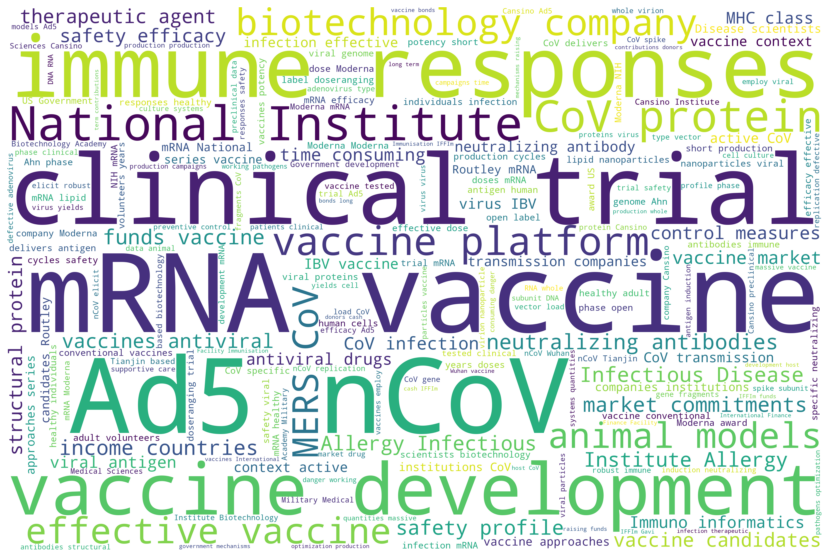

**Query : Assays to evaluate vaccine immune response and process development for vaccines, alongside suitable animal models in conjunction with therapeutics for COVID 19 or the novel coronavirus**

***COVID-19, an emerging coronavirus infection: advances and prospects in designing and developing vaccines, immunotherapeutics, and therapeutics (2020.03.18):***

> Achievements in the development of vaccines and therapeutic agents for SARS- and MERS-CoV as well as recent ongoing progress for COVID-19 will facilitate the development of effective vaccines and therapeutics against this emerging virus. However, the present scenario of COVID-19 warrants the need for implementing robust preventive and control measures due to the potential for nosocomial infections.77 We need to rely exclusively on preventive measures since considerable time is required before efforts to develop a new vaccine or antiviral agent becomes fruitful.**

,publish_date,title,para_summary,para_similarity
7344,2020-03-18,"COVID-19, an emerging coronavirus infection: advances and prospects in designing and developing vaccines, immunotherapeutics, and therapeutics","Achievements in the development of vaccines and therapeutic agents for SARS- and MERS-CoV as well as recent ongoing progress for COVID-19 will facilitate the development of effective vaccines and therapeutics against this emerging virus. However, the present scenario of COVID-19 warrants the need for implementing robust preventive and control measures due to the potential for nosocomial infections.77 We need to rely exclusively on preventive measures since considerable time is required before efforts to develop a new vaccine or antiviral agent becomes fruitful.",78.921547
7345,2020-03-18,"COVID-19, an emerging coronavirus infection: advances and prospects in designing and developing vaccines, immunotherapeutics, and therapeutics","Researchers are searching for effective and suitable vaccine candidates and therapeutics for controlling the deadly COVID-19. Further research should be directed toward the study of SARS-CoV-2 in suitable animal models for analyzing replication, transmission, and pathogenesis. There are no effective vaccines or specific antiviral drugs for COVID-19.",76.464752
7328,2020-03-18,"COVID-19, an emerging coronavirus infection: advances and prospects in designing and developing vaccines, immunotherapeutics, and therapeutics","CEPI collaborated with Inovio in 2018 to developing DNA vaccine candidates for MERS ($56 M funding). This facilitates easier recognition of antigens by the immune system.36 Other than these ongoing programs, CEPI has announced funding to Moderna for comparing mRNA therapeutics and vaccines. CEPI has collaborated with The University of Queensland in 2019 to develop the molecular clamp vaccine platform against multiple viral pathogens including MERS-CoV ($10 M funding).",76.032028
7322,2020-03-18,"COVID-19, an emerging coronavirus infection: advances and prospects in designing and developing vaccines, immunotherapeutics, and therapeutics","Most of the therapeutic options that are available for managing COVID-19 are based on previous experiences in treating SARS- and MERS-CoV. A major reason for the lack of approved and commercially available vaccines or therapeutic agents against these CoVs might be the relative lack of interest among the pharmaceutical companies.13 These are outbreak scenarios: the demand for drugs or vaccines lasts only for a period while the outbreak lasts. So by the time a new drug or vaccine is developed, there might not be any patients for clinical trials and also no meaningful market for newly discovered drugs. The WHO also recommends the isolation of patients suspected or confirmed for COVID-19.16 The major therapeutic drugs that might be effective in managing COVID-19 include remdesivir, lopinavir/ritonavir alone or in combination with interferon-β, convalescent plasma, and mAbs.17 Nevertheless, before utilizing these drugs for COVID-19 pneumonia patients, clinical efficacy, and safety studies should be conducted. According to WHO guidelines, infected patients will receive supportive care including oxygen therapy, fluid therapy, and antibiotics for treating secondary bacterial infections. The number of affected people will also be a small proportion of the global drug and vaccine market.",75.427399
7341,2020-03-18,"COVID-19, an emerging coronavirus infection: advances and prospects in designing and developing vaccines, immunotherapeutics, and therapeutics","A major limiting factor in the quest for identifying an ideal vaccine or therapeutic agent is time. It may take months to even several years for researchers to develop, produce, standardize, evaluate, approve, and commercialize therapeutic agents for COVID-19. Furthermore, RNA synthesis inhibitors (like 3TC, TDF), remdesivir, neuraminidase inhibitors, peptide (EK1), anti-inflammatory drugs, abidol, Chi

In [49]:
from sklearn.metrics.pairwise import cosine_similarity
from scipy.spatial import distance
from IPython.display import display, Markdown
no_of_docs = 30
no_of_paras = 10

# load the medical model for NER
medical = en_core_sci_sm.load()

# iterate the sub-task queries
for sub_task_id, sub_task in enumerate(sub_tasks):  
    # compute embedding of sub-task
    query_vector = model.embed_sentence(sub_task)
    selected_paper_ids = get_documents_clusters_by_titles(sub_task, no_of_docs)
    
#     display_time_plots(sub_tasks_names[sub_task_id])
    
    df_paragraphs = get_paragraphs_cluster(sub_task, selected_paper_ids, no_of_paras)

    shortlisted_body_paras = df_paragraphs["paragraph"].values
    para_summ = []
    entities_list = []
    for para in shortlisted_body_paras:
        summ, para_entities = summarize_paragraph(para)
        para_summ.append(summ)
        entities_list.append(" ".join(para_entities))
    
    depict_word_cloud(entities_list, sub_tasks_names[sub_task_id])
    
    df_paragraphs["para_summary"] = para_summ
    df_paragraphs.to_csv("/kaggle/working/subtask_"+sub_tasks_names[sub_task_id]+"_answers.csv", index=False)
    display(Markdown("**Query : "+sub_task+"**"))

    if len(df_paragraphs) == 0:
        display(Markdown("No answer"))
    else:
        
        t= pd.to_datetime(str(df_paragraphs['publish_date'].values[0])) 
        timestring = t.strftime('%Y.%m.%d')
        display(Markdown("***"+ df_paragraphs['title'].values[0] + " (" + timestring + "):***"))
        display(Markdown("> "+ df_paragraphs['para_summary'].values[0] +"**"))
        display(df_paragraphs[['publish_date', 'title', 'para_summary', 'para_similarity']])